# Group 27 – EDA Draft (Martim): Data Quality & Cleaning

**Goal of this notebook:** understand the quality of the ACDC dataset, fix what can be fixed, and give the team
a reusable `clean_data()` function and a cleaned file to work on.

Most of the methods come from the course labs (lab03 exploration, lab04/05 visualization, lab06 preprocessing).
Two steps needed pandas tools that the labs do not cover: **turning `lifetime_value` text into numbers** and
**reading the dates**. Those cells are marked *(beyond the labs)* and every choice is explained next to the code.

**How we worked:** first we look (sections 4–6), then we decide (sections 7–9), and every decision points back
to an output that justifies it.

## 1. Setup

In [1]:
# Remember: library imports are ALWAYS at the top of the script, no exceptions!
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil

from sklearn.impute import KNNImputer

# for better resolution plots
%config InlineBackend.figure_format = 'retina'

sns.set_theme()

## 2. Reading the Data

The file uses `;` as separator (opening it with the default `,` puts everything in one column).

In [2]:
# path to the dataset (relative to notebooks/drafts/)
data_path = os.path.join("..", "..", "data", "acdc_dataset.csv")

df = pd.read_csv(data_path, sep=";")

# we keep an untouched copy so we can always compare "before vs after"
df_original = df.copy()

## 3. Metadata

- *member_id* – Unique identifier of each member
- *age* – Age of the member at the extraction date
- *gender* – Gender of the member
- *country* – Country where the member (or their company) is based
- *industry* – Industry sector the member works in
- *is_team_account* – Whether the membership is held by a team/company account
- *n_colleagues_on_account* – Number of colleagues sharing the account
- *plan_tier* – Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)
- *plan_days_per_week* – Days per week the plan entitles the member to use the space
- *membership_start* / *membership_end* – Dates the membership began / first ended
- *last_badge_swipe* – Date of the most recent physical entry
- *days_since_last_visit* – Days since the last recorded visit
- *total_visits* – Total visits over the whole membership
- *avg_weekly_visits* – Average visits per week over the membership
- *entitled_visits_last_period* / *actual_visits_last_period* – Visits entitled / made in the last period
- *meeting_room_hours* / *event_space_hours* – Hours of meeting-room / event-space usage
- *guest_passes_issued* – Number of guest passes issued
- *uses_\** – Whether the member used each add-on (meeting rooms, event space, guest passes, print,
  mail handling, phone booths, day passes, storage, bike locker)
- *n_renewals* – Number of times the membership was renewed
- *lifetime_value* – Total revenue attributed to the member

## 4. Initial Analysis

In [3]:
df.head()

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74


In [4]:
df.shape

(15465, 31)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits    

Comparing the data types with the metadata, three things already look wrong:
- `lifetime_value` should be a number but is stored as `object` (text).
- `uses_print` is stored as 0/1 while all the other `uses_*` add-on flags are True/False.
- The three date columns are stored as text.

In [6]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.86,10.39,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.54,1.18,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.39,1.46,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.11,275.53,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.41,182.94,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.78,1.94,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.52,13.48,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80,11.39,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.08,428.17,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.12,26.01,-13.5,0.00,0.00,0.00,602.80


In [7]:
df.describe(include="object").T

,count,unique,top,freq
member_id,15465,15450,CW005845,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


### Feature groups

As in lab03, we split the variables by type, because each type needs a different treatment.

In [8]:
id_feature = "member_id"

date_features = ["membership_start", "membership_end", "last_badge_swipe"]

non_metric_features = ["gender", "country", "industry", "plan_tier"]

bool_features = ["is_team_account",
                 "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print",
                 "uses_mail_handling", "uses_phone_booths", "uses_day_passes", "uses_storage",
                 "uses_bike_locker"]

# lifetime_value is listed here because it is numeric by nature; it is converted from text in section 5.3
metric_features = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit",
                   "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
                   "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
                   "guest_passes_issued", "n_renewals", "lifetime_value"]

# sanity check: every column belongs to exactly one group
all_groups = [id_feature] + date_features + non_metric_features + bool_features + metric_features
print("Columns not assigned:", set(df.columns) - set(all_groups))
print("Columns assigned twice:", len(all_groups) - len(set(all_groups)))

Columns not assigned: set()
Columns assigned twice: 0


## 5. Data Quality Checks

### 5.1 Duplicates

In [9]:
# fully duplicated rows
df.duplicated().sum()

np.int64(15)

In [10]:
# duplicated member ids (each member should appear only once)
df[id_feature].duplicated().sum()

np.int64(15)

In [11]:
# same number of duplicated rows and duplicated ids: are they exact copies of the same member?
dup_ids = df.loc[df[id_feature].duplicated(), id_feature]
df.loc[df[id_feature].isin(dup_ids)].sort_values(id_feature).head(6)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
959,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,...,False,True,0,False,False,False,False,False,0,505.28
15453,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,...,False,True,0,False,False,False,False,False,0,505.28
15454,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,...,False,True,0,False,False,False,False,False,0,231.86
1428,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,...,False,True,0,False,False,False,False,False,0,231.86
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14
3985,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14


In [12]:
# they are exact copies (probably the same record loaded twice), so we simply drop them
df.drop_duplicates(inplace=True)
print("Rows after dropping duplicates:", df.shape[0])
print("Remaining duplicated ids:", df[id_feature].duplicated().sum())

Rows after dropping duplicates: 15450
Remaining duplicated ids: 0


### 5.2 Missing Values

In [13]:
# empty strings are missing values too (lab03), then we count NaNs per column
df.replace("", np.nan, inplace=True)

missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
})
missing.loc[missing["n_missing"] > 0].sort_values("n_missing", ascending=False)

,n_missing,pct_missing
meeting_room_hours,1295,8.38
guest_passes_issued,1269,8.21
lifetime_value,1040,6.73
age,557,3.61
gender,530,3.43
country,429,2.78
plan_tier,105,0.68


In [14]:
print("Rows with any missing value:", df.isna().any(axis=1).sum(),
      f"({df.isna().any(axis=1).mean() * 100:.1f}% of rows)")

Rows with any missing value: 4364 (28.2% of rows)


Dropping every incomplete row would cost more than a quarter of the data, so we will impute instead.

A question before imputing: are the missing usage values related to the add-on flags? If a member never used
meeting rooms, a missing number of meeting-room hours most likely just means 0.

In [15]:
pd.crosstab(df["meeting_room_hours"].isna(), df["uses_meeting_rooms"])

uses_meeting_rooms,False,True
meeting_room_hours,,
False,9290,4865
True,902,393


In [16]:
pd.crosstab(df["guest_passes_issued"].isna(), df["uses_guest_passes"])

uses_guest_passes,False,True
guest_passes_issued,,
False,11573,2608
True,1066,203


Most missing values belong to members who never used the add-on, so for them 0 is the logical value (section 7).

### 5.3 Data Types

In [17]:
# uses_print is stored as 0/1: check its values before converting
df["uses_print"].value_counts()

uses_print
0    10458
1     4992
Name: count, dtype: int64

In [18]:
# only 0 and 1 and no missing values, so it becomes a plain True/False column like the other add-on flags
df["uses_print"] = df["uses_print"].astype(bool)
df[bool_features].dtypes

is_team_account       bool
uses_meeting_rooms    bool
uses_event_space      bool
uses_guest_passes     bool
uses_print            bool
uses_mail_handling    bool
uses_phone_booths     bool
uses_day_passes       bool
uses_storage          bool
uses_bike_locker      bool
dtype: object

#### Dates *(beyond the labs)*

The date columns mix two formats: `2021-08-01` and `01/01/2021`. The second one is ambiguous: it could be
day/month or month/day. We let the data tell us.

In [19]:
# In the dates with "/", if the FIRST number is sometimes above 12 it can only be the day (dd/mm/yyyy).
# If the SECOND number were ever above 12, the format would be mm/dd/yyyy instead.
for feat in date_features:
    slash_dates = df.loc[df[feat].str.contains("/"), feat]
    first_number = slash_dates.str.split("/").str[0].astype(int)
    second_number = slash_dates.str.split("/").str[1].astype(int)
    print(f"{feat}: {len(slash_dates)} dates with '/' | first number > 12: {(first_number > 12).sum()}"
          f" | second number > 12: {(second_number > 12).sum()}")

membership_start: 637 dates with '/' | first number > 12: 366 | second number > 12: 0
membership_end: 461 dates with '/' | first number > 12: 276 | second number > 12: 0
last_badge_swipe: 637 dates with '/' | first number > 12: 440 | second number > 12: 0


In [20]:
# The first number goes above 12 and the second never does, so the format is dd/mm/yyyy.
# We parse each format explicitly instead of letting pandas guess, so no date is read the wrong way round.
for feat in date_features:
    iso_format = pd.to_datetime(df[feat], format="%Y-%m-%d", errors="coerce")
    day_first_format = pd.to_datetime(df[feat], format="%d/%m/%Y", errors="coerce")
    df[feat] = iso_format.fillna(day_first_format)

# every date must have matched one of the two formats, otherwise it would now be missing
df[date_features].isna().sum()

membership_start    0
membership_end      0
last_badge_swipe    0
dtype: int64

In [21]:
df[date_features].describe()

,membership_start,membership_end,last_badge_swipe
count,15450,15450,15450
mean,2022-03-15 18:14:12.815534080,2009-05-25 17:09:15.029126144,2023-02-13 20:05:41.126213632
min,2021-01-01 00:00:00,1970-01-01 00:00:00,2020-09-06 00:00:00
25%,2021-06-02 00:00:00,1970-01-01 00:00:00,2022-08-11 00:00:00
50%,2022-01-06 00:00:00,2022-08-21 00:00:00,2023-05-06 00:00:00
75%,2022-11-03 00:00:00,2023-06-09 00:00:00,2023-10-17 00:00:00
max,2023-12-30 00:00:00,2024-01-01 00:00:00,2024-04-28 00:00:00


The data covers memberships starting between 2021 and 2023, as described in the project guidelines.
Two things to investigate in section 5.6:
- many `membership_end` dates are `1970-01-01`, which is clearly a placeholder;
- some badge swipes happen in 2020 (before any membership started) or in 2024.

#### `lifetime_value` *(beyond the labs)*

There are more than 11,000 different values, so instead of listing them we replace every digit by `9`.
This shows the different *formats* the values are written in.

In [22]:
ltv_text = df["lifetime_value"].dropna()
ltv_text.str.replace(r"\d", "9", regex=True).value_counts()

lifetime_value
9999.99         4547
999.99          4412
9               1724
99999.99        1535
999.9            472
9999.9           447
99.99            244
999              208
999.99 €         168
99999.9          130
9,999.99          82
9999.99 €         65
9999              48
99999             46
-999.99           44
99.9              39
99                31
999999            27
99999.99 €        26
-9999.99          25
99,999.99         25
9.99 €            18
9999999           16
99.99 €           14
999999.99          3
-999.9             3
-99999.99          2
-999               2
-9999.9            2
-9999              1
9,999,999.99       1
-99.99             1
-9,999.99          1
-99,999.99         1
Name: count, dtype: int64

In [23]:
# Formats found: plain numbers, numbers followed by " €" and numbers with "," as thousands separator.
# The comma is never a decimal separator (the decimals always come after a "."), so we can just remove it.
n_missing_before = df["lifetime_value"].isna().sum()

df["lifetime_value"] = (df["lifetime_value"]
                        .str.replace("€", "", regex=False)
                        .str.replace(",", "", regex=False)
                        .str.strip()
                        .astype(float))

print("Missing before:", n_missing_before, "| missing after:", df["lifetime_value"].isna().sum(),
      "-> no value was lost in the conversion")
df["lifetime_value"].describe().round(2)

Missing before: 1040 | missing after: 1040 -> no value was lost in the conversion


count      14410.00
mean        6398.77
std        62789.64
min       -13440.24
25%          252.73
50%          825.12
75%         5057.34
max      3371260.00
Name: lifetime_value, dtype: float64

The conversion worked, but the values themselves look suspicious: negative revenue, a maximum of more than
3 million euros and many zeros. We investigate them in section 5.7.

### 5.4 Inconsistent Categories

Checking the unique values of each categorical feature.

In [24]:
for feat in non_metric_features:
    print(f"--- {feat} ({df[feat].nunique()} unique values) ---")
    print(df[feat].value_counts(dropna=False).to_string(), "\n")

--- gender (12 unique values) ---
gender
Female     7405
Male       6166
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8 

--- country (33 unique values) ---
country
Portugal           9950
United Kingdom     1104
Germany             850
Spain               711
France              506
Netherlands         463
NaN                 429
Other (Europe)      429
Ireland             232
portugal            155
Portucal            142
PT                  130
portugal            122
germany              24
other (europe)       22
france               18
united kingdom       16
DE                   14
UK                   14
NL                   13
Deutschland          13
GB                   12
Espana               10
U.K.                 10
FR                    9
United kingdom        9
ES                    8
España                7
IE                    6
ireland   

The same category is written in many ways (capital letters, extra spaces, abbreviations, other languages,
typos like `Portucal`). We map every variant to one standard label with `.replace()`.

In [25]:
gender_map = {
    "female": "Female", "F": "Female", " Female": "Female",
    "male": "Male", "M": "Male", " Male": "Male",
    "other": "Other", " Other": "Other", "O": "Other",
}

country_map = {
    "portugal ": "Portugal", "portugal": "Portugal", "Portucal": "Portugal", "PT": "Portugal",
    "united kingdom": "United Kingdom", "United kingdom": "United Kingdom", "UK": "United Kingdom",
    "U.K.": "United Kingdom", "GB": "United Kingdom",
    "germany": "Germany", "DE": "Germany", "Deutschland": "Germany",
    "spain": "Spain", "ES": "Spain", "Espana": "Spain", "España": "Spain",
    "france": "France", "FR": "France",
    "netherlands": "Netherlands", "NL": "Netherlands", "The Netherlands": "Netherlands",
    "Holland": "Netherlands",
    "ireland": "Ireland", "IE": "Ireland",
    "other (europe)": "Other (Europe)",
}

industry_map = {
    "INFORMATION TECHNOLOGY": "Information Technology", "information technology": "Information Technology",
    "Information technology": "Information Technology", "IT": "Information Technology",
    "Tech": "Information Technology",
    "CONSULTING": "Consulting", "consulting": "Consulting",
    "MARKETING & PR": "Marketing & PR", "marketing & pr": "Marketing & PR", "Marketing & Pr": "Marketing & PR",
    "Marketing/PR": "Marketing & PR", "Marketing and PR": "Marketing & PR",
    "DESIGN & CREATIVE": "Design & Creative", "design & creative": "Design & Creative",
    "Design/Creative": "Design & Creative", "Design and Creative": "Design & Creative",
    "FINANCE": "Finance", "finance": "Finance",
    "LEGAL": "Legal", "legal": "Legal",
    "EDUCATION": "Education", "education": "Education",
    "HEALTH": "Health", "health": "Health",
    "REAL ESTATE": "Real Estate", "real estate": "Real Estate", "RealEstate": "Real Estate",
    "Real-Estate": "Real Estate",
    "OTHER": "Other", "other": "Other",
    "UNKNOWN": "Unknown", "unknown": "Unknown",
}

plan_tier_map = {
    "HOT_DESK": "hot_desk", "Hot Desk": "hot_desk", "hotdesk": "hot_desk",
    "Flex": "flex", "FLEX": "flex",
    "DEDICATED_DESK": "dedicated_desk", "Dedicated Desk": "dedicated_desk", "dedicateddesk": "dedicated_desk",
    "FULL_TIME": "full_time", "Full Time": "full_time", "fulltime": "full_time",
    "PRIVATE_OFFICE": "private_office", "Private Office": "private_office", "privateoffice": "private_office",
}

category_maps = {"gender": gender_map, "country": country_map,
                 "industry": industry_map, "plan_tier": plan_tier_map}

for feat, mapping in category_maps.items():
    df[feat] = df[feat].replace(mapping)

In [26]:
# check the result: each feature should now only have its standard labels
for feat in non_metric_features:
    print(f"{feat}: {sorted(df[feat].dropna().unique())}")

gender: ['Female', 'Male', 'Other']
country: ['France', 'Germany', 'Ireland', 'Netherlands', 'Other (Europe)', 'Portugal', 'Spain', 'United Kingdom']
industry: ['Consulting', 'Design & Creative', 'Education', 'Finance', 'Health', 'Information Technology', 'Legal', 'Marketing & PR', 'Other', 'Real Estate', 'Unknown']
plan_tier: ['dedicated_desk', 'flex', 'full_time', 'hot_desk', 'private_office']


`industry` keeps an `Unknown` category that comes from the source system itself. We keep it as it is:
it is a real answer ("not declared"), not a gap we created.

### 5.5 Coherence Checks (numeric and categorical)

Rules that every row should respect. First, does `plan_days_per_week` match the plan?

In [27]:
pd.crosstab(df["plan_tier"], df["plan_days_per_week"])

plan_days_per_week,0,2,3,5,7,9
plan_tier,,,,,,
dedicated_desk,3,0,0,1540,0,6
flex,20,0,5407,0,0,22
full_time,5,0,0,2456,0,10
hot_desk,14,5183,0,0,0,15
private_office,1,0,0,0,662,1


Each tier has one clear number of days per week (hot_desk = 2, flex = 3, dedicated_desk = 5,
full_time = 5, private_office = 7). The few rows with 0 or 9 days are errors (a week has 7 days).

In [28]:
tier_days = {"hot_desk": 2, "flex": 3, "dedicated_desk": 5, "full_time": 5, "private_office": 7}


def expected_plan_days(data):
    # days per week each row's plan_tier entitles to (NaN when the tier is missing)
    expected = pd.Series(np.nan, index=data.index)
    for tier, days in tier_days.items():
        expected.loc[data["plan_tier"] == tier] = days
    return expected


expected_days = expected_plan_days(df)

# each rule is True for the rows that BREAK it
coherence_rules = {
    "age < 18 or age > 100":
        (df["age"] < 18) | (df["age"] > 100),
    "negative n_colleagues_on_account":
        df["n_colleagues_on_account"] < 0,
    "negative total_visits":
        df["total_visits"] < 0,
    "negative meeting_room_hours":
        df["meeting_room_hours"] < 0,
    "negative event_space_hours":
        df["event_space_hours"] < 0,
    "negative guest_passes_issued":
        df["guest_passes_issued"] < 0,
    "negative n_renewals":
        df["n_renewals"] < 0,
    "negative days_since_last_visit":
        df["days_since_last_visit"] < 0,
    "negative lifetime_value":
        df["lifetime_value"] < 0,
    "plan_days_per_week not matching plan_tier":
        df["plan_tier"].notna() & (df["plan_days_per_week"] != expected_days),
    "avg_weekly_visits > 7 (more than one visit per day)":
        df["avg_weekly_visits"] > 7,
    "total_visits > 1095 (more than one visit per day in 3 years)":
        df["total_visits"] > 3 * 365,
    "actual_visits_last_period > entitled_visits_last_period":
        df["actual_visits_last_period"] > df["entitled_visits_last_period"],
    "uses_meeting_rooms False but meeting_room_hours > 0":
        (df["uses_meeting_rooms"] == False) & (df["meeting_room_hours"] > 0),
    "uses_event_space False but event_space_hours > 0":
        (df["uses_event_space"] == False) & (df["event_space_hours"] > 0),
    "uses_guest_passes False but guest_passes_issued > 0":
        (df["uses_guest_passes"] == False) & (df["guest_passes_issued"] > 0),
    "is_team_account False but n_colleagues_on_account > 0":
        (df["is_team_account"] == False) & (df["n_colleagues_on_account"] > 0),
}

coherence = pd.DataFrame({"n_rows": {rule: mask.sum() for rule, mask in coherence_rules.items()}})
coherence["pct_rows"] = (coherence["n_rows"] / df.shape[0] * 100).round(2)
coherence.sort_values("n_rows", ascending=False)

,n_rows,pct_rows
negative n_colleagues_on_account,565,3.66
age < 18 or age > 100,143,0.93
plan_days_per_week not matching plan_tier,97,0.63
negative lifetime_value,82,0.53
negative n_renewals,66,0.43
negative days_since_last_visit,56,0.36
uses_meeting_rooms False but meeting_room_hours > 0,55,0.36
negative total_visits,42,0.27
avg_weekly_visits > 7 (more than one visit per day),42,0.27
negative meeting_room_hours,16,0.10


In [29]:
any_rule = pd.concat(coherence_rules.values(), axis=1).any(axis=1)
print("Rows breaking at least one rule:", any_rule.sum(), f"({any_rule.mean() * 100:.1f}%)")

Rows breaking at least one rule: 1083 (7.0%)


In [30]:
# the extreme ages: babies and people older than any human ever recorded
df["age"].value_counts().sort_index()

age
1.0       2
2.0       8
3.0      26
4.0      26
5.0       4
         ..
144.0     2
145.0     1
146.0     2
147.0     1
149.0     1
Name: count, Length: 84, dtype: int64

`n_colleagues_on_account = -1` is the most frequent problem. Does it depend on the type of account?

In [31]:
pd.crosstab(df["is_team_account"], df["n_colleagues_on_account"])

n_colleagues_on_account,-1,0,1,2,3,4,5,6,7,8,9
is_team_account,,,,,,,,,,,
False,412,10688,0,0,0,0,0,0,0,0,0
True,153,0,1758,1116,727,381,142,56,14,2,1


Individual accounts never have colleagues (all other values are 0), so on an individual account -1 can only
mean 0. On a team account the real number is unknown (it is at least 1).

Next, `entitled_visits_last_period` should follow from the plan: days per week × weeks in the period.

In [32]:
# entitled visits / days per week = length of the "last period" in weeks (only rows where days match the tier)
consistent_days = df["plan_days_per_week"] == expected_days
period_weeks = (df["entitled_visits_last_period"] / df["plan_days_per_week"])[consistent_days]
period_weeks.round(1).value_counts().head()

8.7    11879
7.6       94
8.4       91
8.0       89
8.1       77
Name: count, dtype: int64

In [33]:
# the exact length of a full period (the rounded value 8.7 is the most frequent one)
weeks_last_period = period_weeks[period_weeks.round(1) == period_weeks.round(1).mode()[0]].median()

above_entitlement = consistent_days & (
    df["entitled_visits_last_period"] > df["plan_days_per_week"] * weeks_last_period + 0.05)
print("Weeks in a full period:", round(weeks_last_period, 3))
print("Rows (with days matching the tier) above the plan's entitlement:", above_entitlement.sum())

Weeks in a full period: 8.696
Rows (with days matching the tier) above the plan's entitlement: 0


A full period is about 8.7 weeks (two months), and most entitlements are exactly *days × 8.7*. Smaller values
are partial periods (members who joined or left during the period), and no row goes above its plan's entitlement.

That was for rows whose days match the tier. What about the rows with the impossible 0 or 9 days: was their
entitlement calculated with the wrong days too?

In [34]:
ent = "entitled_visits_last_period"
nine_days = df["plan_tier"].notna() & (df["plan_days_per_week"] == 9)
zero_days = df["plan_tier"].notna() & (df["plan_days_per_week"] == 0)

# the most a member can be entitled to: a full period with the tier's days
full_period = expected_days * weeks_last_period
above_full = df[ent] > full_period + 0.05

print("9 days:", nine_days.sum(), "rows")
print("  entitlement that fits the tier's days:", (nine_days & ~above_full).sum())
print("  entitlement above a full period of the tier's days (impossible):", (nine_days & above_full).sum())
print("  weeks implied by the RECORDED 9 days for those rows:")
print((df.loc[nine_days & above_full, ent] / 9).round(2).value_counts().head(3).to_string(), "\n")

print("0 days:", zero_days.sum(), "rows")
print("  entitlement above a full period of the tier's days:", (zero_days & above_full).sum())
print("  rows with 0 entitled visits:", (zero_days & (df[ent] == 0)).sum(),
      "| rows with 0 entitled visits anywhere else:", ((df[ent] == 0) & ~zero_days).sum())

9 days: 54 rows
  entitlement that fits the tier's days: 24
  entitlement above a full period of the tier's days (impossible): 30
  weeks implied by the RECORDED 9 days for those rows:
entitled_visits_last_period
8.70    27
4.60     1
3.29     1 

0 days: 43 rows
  entitlement above a full period of the tier's days: 0
  rows with 0 entitled visits: 10 | rows with 0 entitled visits anywhere else: 0


- **9 days:** part of these rows have an entitlement that fits the tier, so it is correct. The others are above
  what the tier allows, which is impossible; divided by the recorded 9 days they give exactly one full period
  (8.7 weeks), so they were calculated with the wrong 9 days and must be recalculated with the tier's days.
- **0 days:** the entitlement never goes above what the tier allows, so it is correct, except for the rows with
  exactly 0 entitled visits. That value appears nowhere else in the data: it was calculated with the wrong 0 days.

Both are fixed in section 7 together with the days.

### 5.6 Dates and Recency

`membership_end = 1970-01-01` appears thousands of times. 1970-01-01 is the "zero date" of many computer
systems, so it is almost certainly a placeholder. Our hypothesis: **it means the member is still active.**

To test it we use `days_since_last_visit`. If it is calculated as *(reference date − last badge swipe)*, then
`last_badge_swipe + days_since_last_visit` gives back the reference date.

In [35]:
placeholder_end = df["membership_end"].dt.year == 1970
print("membership_end = 1970-01-01:", placeholder_end.sum())

# 999 is a suspicious value (see below), so for this test we only use plausible values
valid_days = df["days_since_last_visit"].between(0, 998)
reference = df["last_badge_swipe"] + pd.to_timedelta(df["days_since_last_visit"], unit="D")

# members with the placeholder end date: which reference date do we get?
reference[placeholder_end & valid_days].value_counts().head()

membership_end = 1970-01-01: 3954


2024-01-01    3286
2023-12-31     231
2023-12-28       4
2024-01-06       3
2024-01-02       3
Name: count, dtype: int64

In [36]:
# almost all of them give the same date: the day the data was extracted
extraction_date = reference[placeholder_end & valid_days].mode()[0]
print("Extraction date:", extraction_date.date())

Extraction date: 2024-01-01


In [37]:
# members with a real end date: is the reference date their membership_end? (difference in days)
(reference - df["membership_end"]).dt.days[~placeholder_end & valid_days].value_counts().head()

 0    9855
-1     221
 1     213
 5      11
-2       7
Name: count, dtype: int64

Both parts of the hypothesis hold (almost all differences are 0 or ±1 day, which is just rounding):
- for members with the placeholder, the days are counted up to the **extraction date** → they are **still active**;
- for members who left, the days are counted up to their **`membership_end`**.

This means `days_since_last_visit` can be **recalculated from the dates**, which matters because the column
has problems of its own:

In [38]:
# the most frequent value is 999, far above the typical values: another placeholder
df["days_since_last_visit"].value_counts().head()

days_since_last_visit
999    1298
2      1261
3      1091
1      1090
4       942
Name: count, dtype: int64

In [39]:
df["days_since_last_visit"].describe().round(2)

count    15450.00
mean       117.19
std        275.64
min       -956.00
25%          4.00
50%         13.00
75%         55.00
max       1212.00
Name: days_since_last_visit, dtype: float64

Now the order of the dates. A membership must start before it ends, and the last visit must happen while the
membership is running (and before the data was extracted).

In [40]:
end_date = df["membership_end"].where(~placeholder_end)   # NaT = still active

date_rules = {
    "membership_end before membership_start": end_date < df["membership_start"],
    "last_badge_swipe before membership_start": df["last_badge_swipe"] < df["membership_start"],
    "last_badge_swipe after membership_end": df["last_badge_swipe"] > end_date,
    "last_badge_swipe after the extraction date": df["last_badge_swipe"] > extraction_date,
}

date_check = pd.DataFrame({"n_rows": {rule: mask.sum() for rule, mask in date_rules.items()}})
date_check["pct_rows"] = (date_check["n_rows"] / df.shape[0] * 100).round(2)
date_check

,n_rows,pct_rows
membership_end before membership_start,152,0.98
last_badge_swipe before membership_start,94,0.61
last_badge_swipe after membership_end,213,1.38
last_badge_swipe after the extraction date,34,0.22


In [41]:
any_date_rule = pd.concat(date_rules.values(), axis=1).any(axis=1)
print("Rows with contradictory dates:", any_date_rule.sum(), f"({any_date_rule.mean() * 100:.1f}%)")

Rows with contradictory dates: 333 (2.2%)


In [42]:
# How big are the contradictions? A 1-day difference would suggest a typo we could fix.
pd.DataFrame({
    "end before start (days)":
        (df["membership_start"] - end_date).dt.days[date_rules["membership_end before membership_start"]].describe(),
    "swipe before start (days)":
        (df["membership_start"] - df["last_badge_swipe"]).dt.days[date_rules["last_badge_swipe before membership_start"]].describe(),
    "swipe after end (days)":
        (df["last_badge_swipe"] - end_date).dt.days[date_rules["last_badge_swipe after membership_end"]].describe(),
}).round(1)

,end before start (days),swipe before start (days),swipe after end (days)
count,152.0,94.0,213.0
mean,45.6,65.8,293.0
std,27.6,34.2,325.8
min,2.0,2.0,2.0
25%,21.0,38.5,47.0
50%,47.5,66.5,105.0
75%,71.0,93.8,528.0
max,89.0,120.0,1160.0


The gaps are weeks or months, not 1-day typos. We cannot know *which* of the dates is wrong in each row,
so they cannot be repaired reliably (decision in section 7).

Do the visit numbers agree with the dates? `avg_weekly_visits` should be `total_visits` divided by the number
of weeks as a member.

In [43]:
weeks_member = (end_date.fillna(extraction_date) - df["membership_start"]).dt.days / 7

# compare only rows where both values are plausible and the dates are clean
plausible_visits = (df["total_visits"] > 0) & (df["avg_weekly_visits"] <= 7) & (weeks_member >= 1) & ~any_date_rule
visits_ratio = df["avg_weekly_visits"] / (df["total_visits"] / weeks_member)
visits_ratio[plausible_visits].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(3)

0.01    0.857
0.05    0.939
0.25    0.995
0.50    1.000
0.75    1.007
0.95    1.078
0.99    1.201
dtype: float64

The ratio is 1.00 for the typical member and stays close to 1 for almost everyone: the two visit columns agree
with each other **and** with the dates. This is good news for the date cleaning, and it also means that when one of
the two visit values is missing, it can be rebuilt from the other (section 9).

### 5.7 `lifetime_value`

Our hypothesis: the revenue of a member is basically **monthly plan price × number of months** as a member.
If that is true, the value per month should be very similar inside each plan tier.
We only use rows with clean dates, a positive value and at least one month of membership for this check.

In [44]:
# 30.44 = average number of days in a month; active members are measured up to the extraction date
tenure_months = (end_date.fillna(extraction_date) - df["membership_start"]).dt.days / 30.44

reliable_ltv = (df["lifetime_value"] > 0) & (tenure_months >= 1) & ~any_date_rule
ltv_per_month = df["lifetime_value"] / tenure_months

ltv_per_month[reliable_ltv].groupby(df["plan_tier"]).describe(percentiles=[.05, .25, .5, .75, .95]).round(1)

,count,mean,std,min,5%,25%,50%,75%,95%,max
plan_tier,,,,,,,,,,
dedicated_desk,1163.0,599.4,2739.6,349.1,349.9,373.5,407.2,449.4,542.8,46396.2
flex,4144.0,407.2,2074.7,175.5,179.5,187.8,204.8,227.7,485.1,59302.5
full_time,1809.0,655.2,3774.7,272.5,279.7,294.2,312.9,354.7,589.9,93717.9
hot_desk,4081.0,265.0,1744.3,116.4,119.2,120.6,132.6,155.1,435.7,78310.3
private_office,473.0,1502.2,7572.9,649.7,665.6,683.2,702.7,728.4,825.9,83255.5


Inside each tier, the middle 50% of members (25% to 75% columns) are within about 20% of the median, and
even the 5th percentile is only 5–15% below it. So the hypothesis holds: **the median value per month of each
tier is a good estimate of the monthly price.**

Something to keep in mind for the business interpretation: `dedicated_desk` costs more per month than
`full_time`, although the metadata lists `full_time` above it. The tier order in the metadata is therefore
not a price order.

We compare every member with that price: a ratio of 1 means "exactly what the plan costs".

In [45]:
tier_monthly_price = ltv_per_month[reliable_ltv].groupby(df["plan_tier"]).median()
expected_ltv = df["plan_tier"].map(tier_monthly_price) * tenure_months
ltv_ratio = df["lifetime_value"] / expected_ltv

print("Estimated monthly price per tier:")
print(tier_monthly_price.round(2).to_string(), "\n")
ltv_ratio[reliable_ltv].quantile([0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).round(2)

Estimated monthly price per tier:
plan_tier
dedicated_desk    407.22
flex              204.85
full_time         312.89
hot_desk          132.56
private_office    702.67 



0.001      0.86
0.010      0.87
0.050      0.88
0.250      0.92
0.500      1.00
0.750      1.13
0.950      2.36
0.990      5.85
0.999    126.12
dtype: float64

Almost nobody pays much *less* than the plan (even the 0.1% lowest ratio is about 0.86), but the top of the
distribution splits into two very different groups: members paying a few times the plan, and a small group
paying around 100 times the plan.

In [46]:
# Group 1: between 3 and 20 times the plan price. Do they use more add-ons than everyone else?
high_ratio = reliable_ltv & ltv_ratio.between(3, 20)
normal_ratio = reliable_ltv & (ltv_ratio < 3)

pd.DataFrame({
    "3x-20x the plan (median)": df.loc[high_ratio, ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]].median(),
    "normal (median)": df.loc[normal_ratio, ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]].median(),
    "3x-20x the plan (mean)": df.loc[high_ratio, ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]].mean(),
    "normal (mean)": df.loc[normal_ratio, ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]].mean(),
}).round(1)

,3x-20x the plan (median),normal (median),3x-20x the plan (mean),normal (mean)
meeting_room_hours,145.8,0.0,226.8,25.5
event_space_hours,73.5,0.0,100.2,2.6
guest_passes_issued,26.0,0.0,47.5,5.0


Yes: these members are heavy add-on users, so the extra revenue is real (add-ons are paid on top of the plan).
**They are kept**, and they are probably one of the most valuable segments.

In [47]:
# Group 2: more than 20 times the plan price. What happens if the decimal point was lost (value / 100)?
extreme_ratio = (df["lifetime_value"] > 0) & (tenure_months > 0) & ~any_date_rule & (ltv_ratio > 20)
print("Members above 20x the plan price:", extreme_ratio.sum())
(ltv_ratio[extreme_ratio] / 100).describe().round(2)

Members above 20x the plan price: 81


count    81.00
mean      1.23
std       0.71
min       0.66
25%       0.92
50%       1.04
75%       1.18
max       5.91
dtype: float64

Divided by 100, the median ratio is ~1 and three quarters of them land between 0.66 and ~1.2 times the plan
price; the highest (up to ~6) are in the range of the heavy add-on users we just saw. The decimal point was lost when the
data was recorded (e.g. `246503` instead of `2465.03`), so these values can be **repaired** instead of deleted.

In [48]:
# Finally, the zeros. Who are the members with lifetime_value = 0?
zero_ltv = (df["lifetime_value"] == 0) & ~any_date_rule
print("Members with lifetime_value = 0:", zero_ltv.sum())
print("Positive values below 30% of the plan price:",
      (reliable_ltv & (ltv_ratio < 0.3)).sum())

pd.DataFrame({
    "tenure_months": tenure_months[zero_ltv].describe(),
    "total_visits": df.loc[zero_ltv, "total_visits"].describe(),
    "n_renewals": df.loc[zero_ltv, "n_renewals"].describe(),
}).round(1)

Members with lifetime_value = 0: 1705
Positive values below 30% of the plan price: 0


,tenure_months,total_visits,n_renewals
count,1705.0,1705.0,1705.0
mean,12.6,97.0,1.0
std,11.5,159.6,1.4
min,0.1,-88.0,-3.0
25%,2.2,7.0,0.0
50%,9.4,24.0,0.0
75%,21.9,113.0,2.0
max,36.0,954.0,6.0


Members with a value of 0 stayed for months (median ~9), visited, and many renewed, so they certainly paid
something.
And no member has a *small* positive value: the values are either "about the plan price" or exactly 0.
**So 0 is a placeholder for "unknown", not real revenue.** The same goes for negative revenue.

In [49]:
# Short memberships (less than a month): do they pay a full month, or only the days they stayed?
short = (df["lifetime_value"] > 0) & (tenure_months > 0) & (tenure_months < 1) & ~any_date_rule
print("Members with less than one month:", short.sum())
print("Median ratio to the prorated price:", round(ltv_ratio[short].median(), 2))

Members with less than one month: 603
Median ratio to the prorated price: 0.96


The ratio is about 1 also for short memberships, so members pay **only for the time they stayed** (prorated).
The formula *monthly price × months* therefore works for every member, which we use to impute missing values.

## 6. Visual Exploration of the Metric Features (before cleaning)

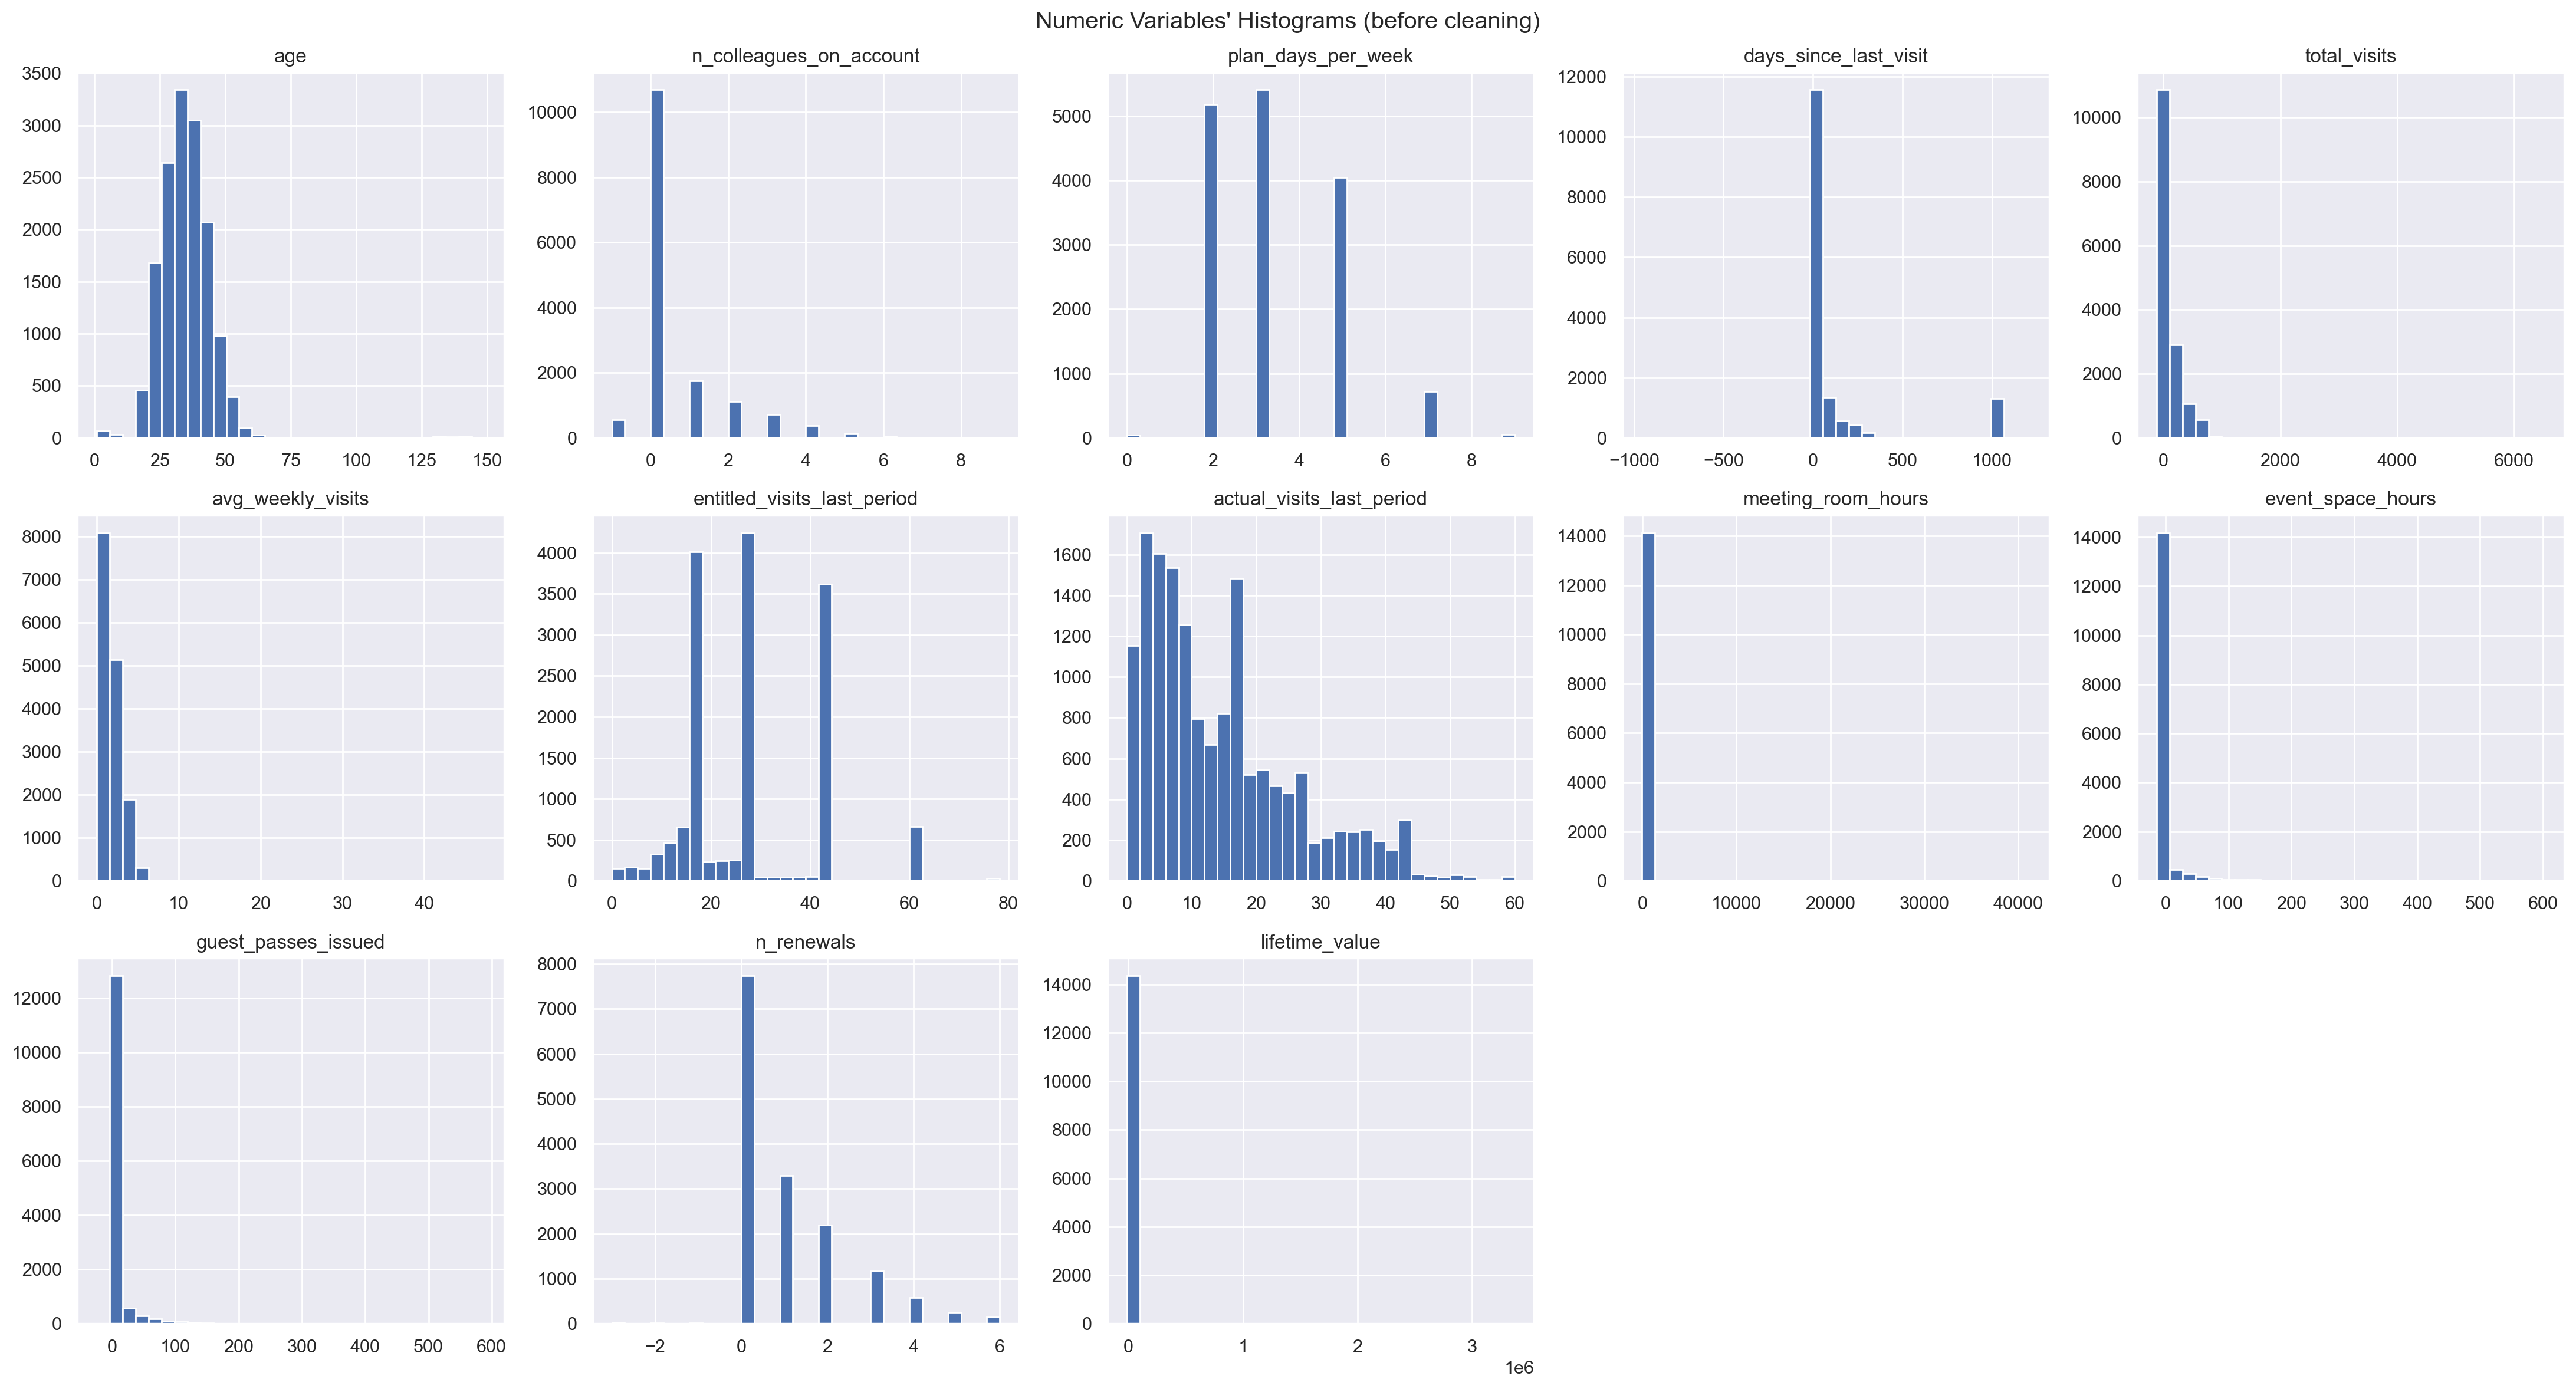

In [50]:
# All Numeric Variables' Histograms in one figure
fig, axes = plt.subplots(3, ceil(len(metric_features) / 3), figsize=(22, 12))

for ax, feat in zip(axes.flatten(), metric_features):
    ax.hist(df[feat].dropna(), bins=30)
    ax.set_title(feat)

# hide the empty slots of the grid
for ax in axes.flatten()[len(metric_features):]:
    ax.set_visible(False)

plt.suptitle("Numeric Variables' Histograms (before cleaning)")
plt.tight_layout()
plt.show()

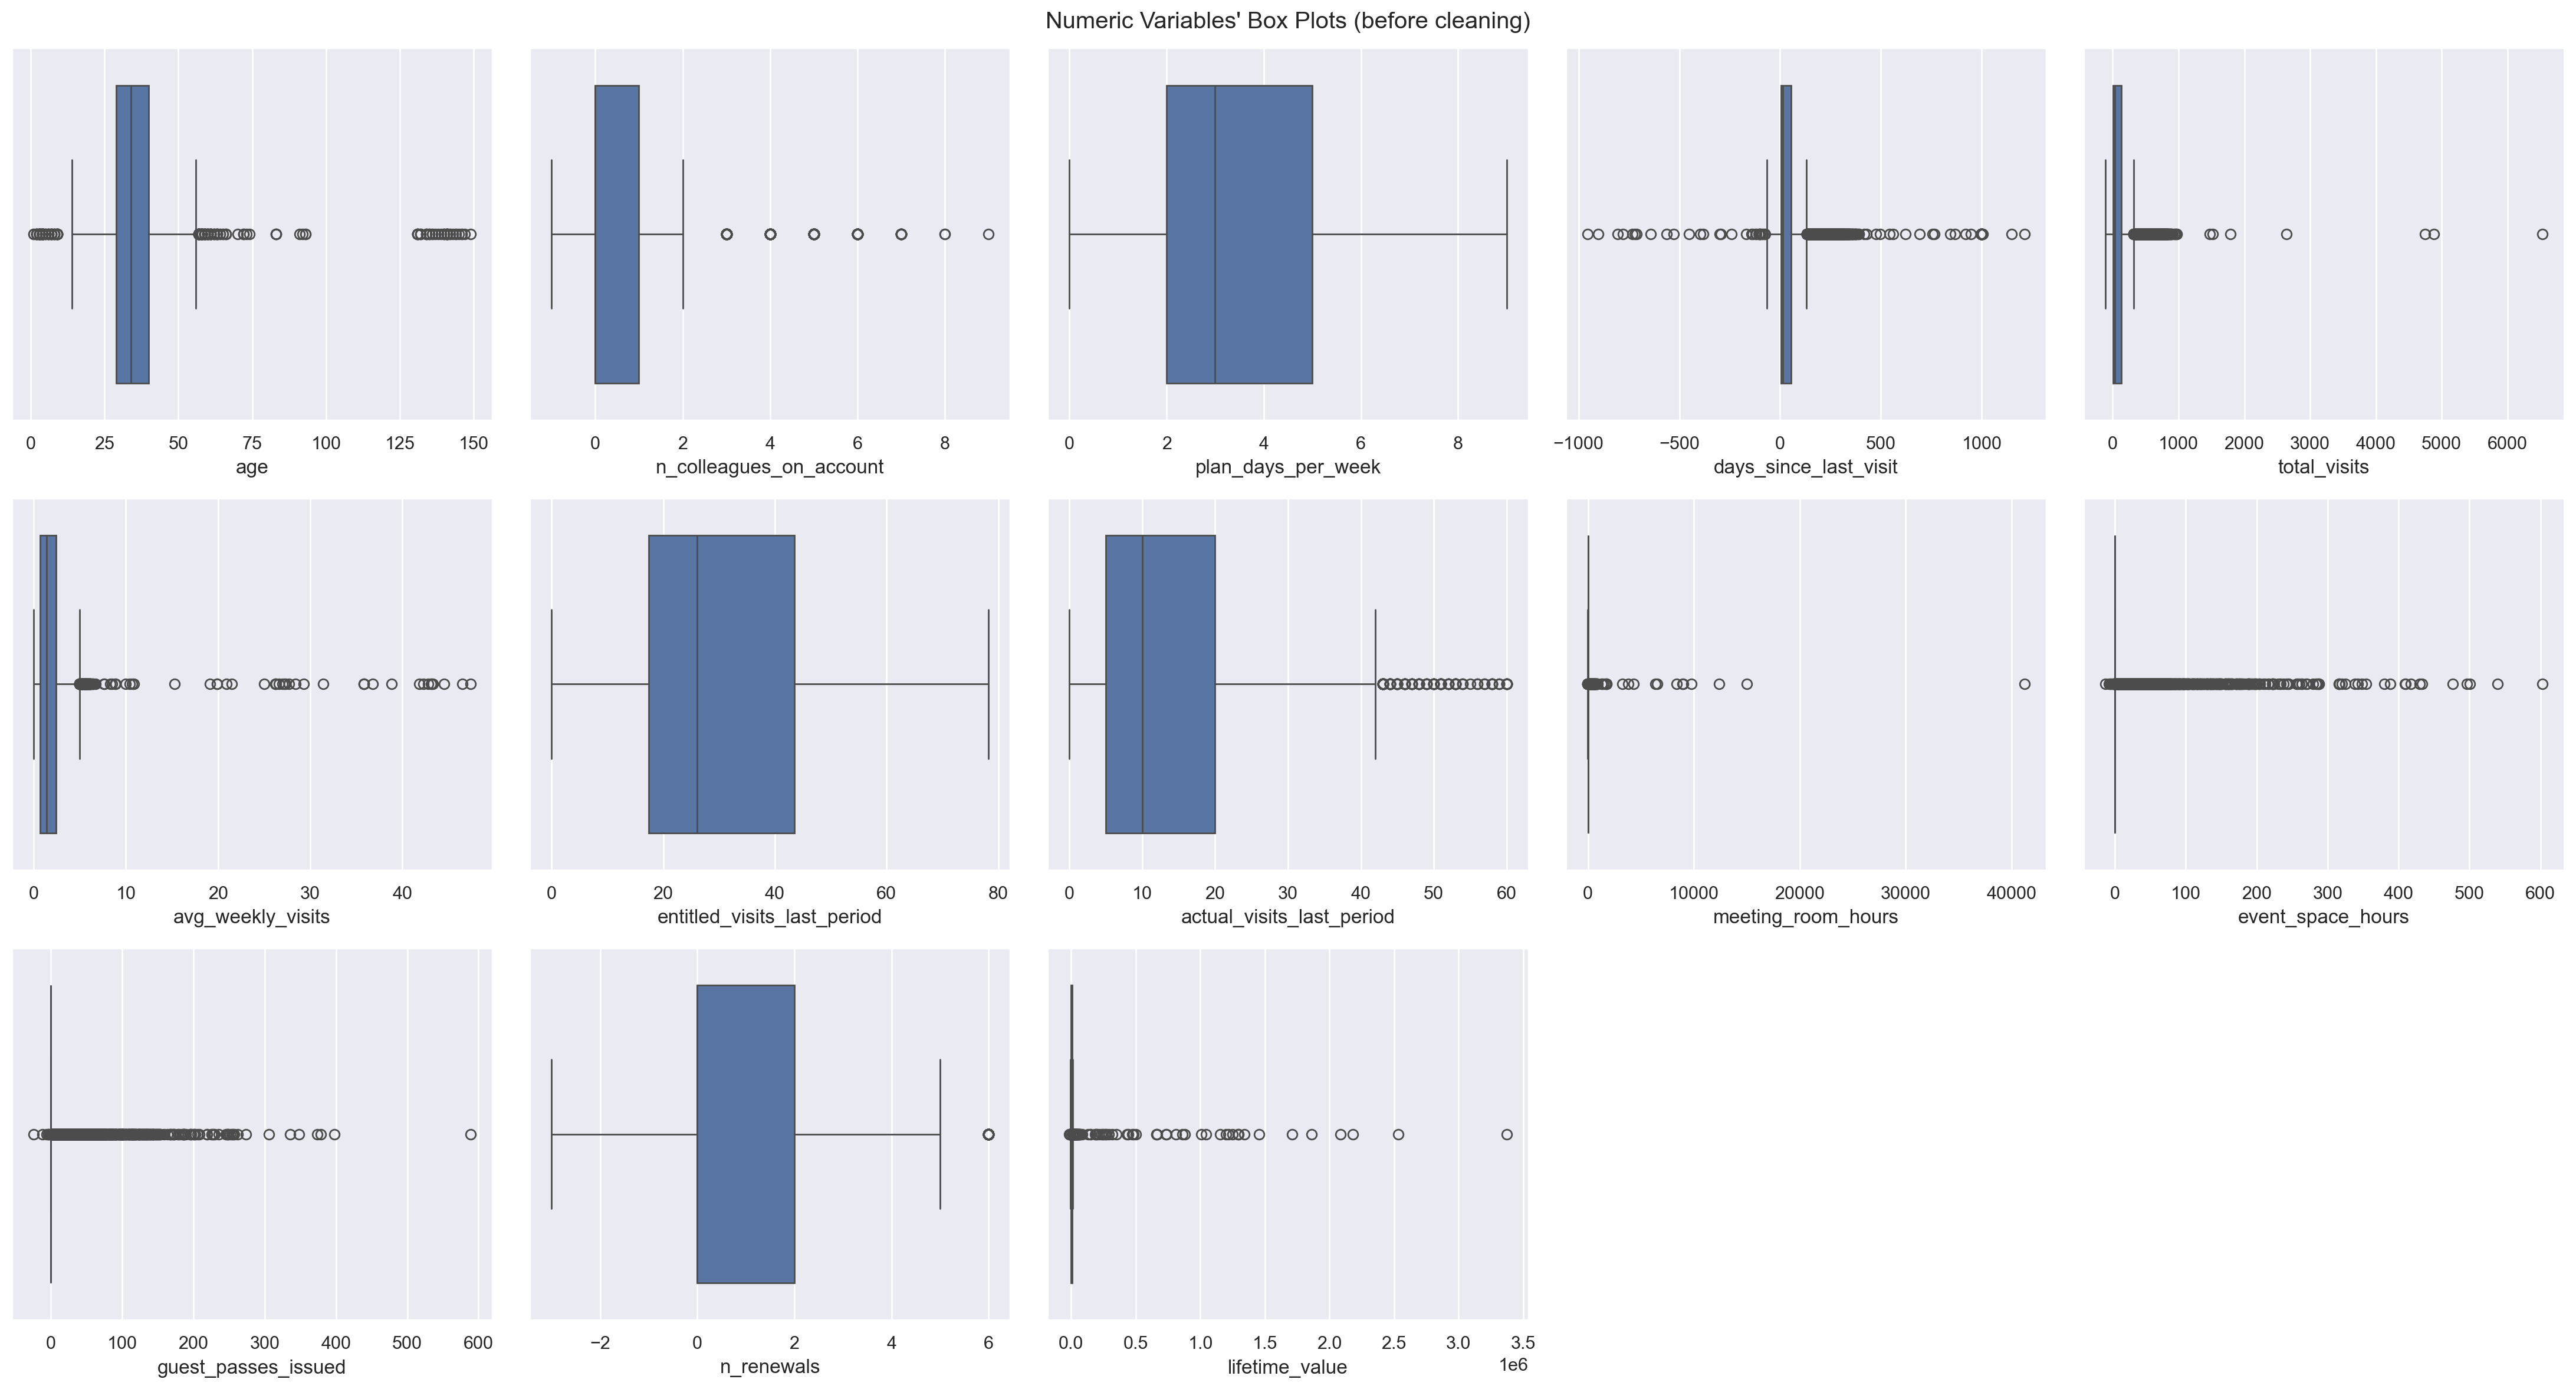

In [51]:
# All Numeric Variables' Box Plots in one figure
fig, axes = plt.subplots(3, ceil(len(metric_features) / 3), figsize=(22, 12))

for ax, feat in zip(axes.flatten(), metric_features):
    sns.boxplot(x=df[feat], ax=ax)

for ax in axes.flatten()[len(metric_features):]:
    ax.set_visible(False)

plt.suptitle("Numeric Variables' Box Plots (before cleaning)")
plt.tight_layout()
plt.show()

### Insights
- **Impossible values appear in almost every feature:** ages from 1 to 149, negative visits, hours, passes,
  renewals and revenue, `n_colleagues_on_account = -1`, and plans with 0 or 9 days per week.
- **`days_since_last_visit` has a block of values near 1000** (the 999 placeholder) and negative values.
- **`lifetime_value` is unreadable on this scale:** a few values in the millions (the lost decimal points from 5.7)
  squeeze everything else into the first bar.
- **`total_visits` and `avg_weekly_visits` have a few physically impossible values** (up to 6,530 visits and
  47 visits per week).
- **Add-on usage (`meeting_room_hours`, `event_space_hours`, `guest_passes_issued`) is zero-inflated:** most members
  never use add-ons, a small group uses them a lot. This "uses add-ons or not" split is a first hint of segments.
- **`plan_days_per_week` and `entitled_visits_last_period` are discrete,** with peaks that follow the plan tiers.
- **`age`, without the impossible values, is bell-shaped** around 25–45 years: a working-age population.

## 7. Data Editing (fixing inconsistent values)

Every decision below comes from the checks in section 5:

| # | Problem | Decision | Why |
|---|---|---|---|
| 1 | Impossible values (ages outside 18–100, negative counts/hours, > 7 visits per week, > 1095 visits) | Set to missing, imputed in section 9 | The rest of the row is fine, so we keep the member and only lose the wrong value |
| 2 | `n_colleagues_on_account = -1` | 0 on individual accounts, missing on team accounts | Individual accounts never have colleagues (5.5) |
| 3 | `plan_days_per_week` not matching the tier | Set to the tier's days; entitlements calculated with the wrong days are recalculated | The tier is the contract; 0 or 9 days are impossible (5.5) |
| 4 | Missing `plan_tier` | Inferred from the days per week; for 5 days (two possible tiers) the most frequent 5-day tier | Keeps tier and days coherent |
| 5 | `uses_meeting_rooms` False with hours > 0 | Flag set to True | Recorded hours prove the room was used |
| 6 | Missing hours/passes for add-ons never used | Set to 0 | Not using an add-on means 0 usage (5.2) |
| 7 | Contradictory dates | Rows removed | We cannot know which date is wrong (5.6); guessing would create fake tenure and recency |
| 8 | `membership_end = 1970-01-01` | Set to empty (NaT) = still active | Proven in 5.6 |
| 9 | `days_since_last_visit` (999 placeholder, negatives) | Recalculated from the dates | The rule behind the column was found in 5.6 |
| 10 | `lifetime_value` 0 or negative | Set to missing, imputed in section 9 | Placeholders, not revenue (5.7) |
| 11 | `lifetime_value` more than 20x the plan price | Divided by 100 | Lost decimal point (5.7) |

In [52]:
# 1. impossible values -> NaN
df.loc[(df["age"] < 18) | (df["age"] > 100), "age"] = np.nan

# days_since_last_visit and lifetime_value are not in this list: they get their own treatment (steps 9-11)
non_negative_features = ["n_colleagues_on_account", "total_visits", "meeting_room_hours",
                         "event_space_hours", "guest_passes_issued", "n_renewals"]

# 2. must run BEFORE the generic negative rule: -1 colleagues on an individual account means 0 colleagues
df.loc[(df["n_colleagues_on_account"] == -1) & (df["is_team_account"] == False), "n_colleagues_on_account"] = 0

for feat in non_negative_features:
    df.loc[df[feat] < 0, feat] = np.nan

df.loc[df["avg_weekly_visits"] > 7, "avg_weekly_visits"] = np.nan
df.loc[df["total_visits"] > 3 * 365, "total_visits"] = np.nan

In [53]:
# 3. plan_days_per_week must match the plan tier
expected_days = expected_plan_days(df)
wrong_days = df["plan_tier"].notna() & (df["plan_days_per_week"] != expected_days)
recorded_days = df["plan_days_per_week"].copy()
df.loc[wrong_days, "plan_days_per_week"] = expected_days[wrong_days]
print("plan_days_per_week values fixed:", wrong_days.sum())

# 9-day rows whose entitlement is above what the tier allows were calculated with 9 days: rescale them (5.5)
rescale = wrong_days & (recorded_days == 9) & (df[ent] > df["plan_days_per_week"] * weeks_last_period + 0.05)
df.loc[rescale, ent] = (df[ent] / 9 * df["plan_days_per_week"])[rescale].round(2)

# 0 entitled visits (only with 0 days): a full period of the tier, the most common case (5.5)
zero_entitled = wrong_days & (recorded_days == 0) & (df[ent] == 0)
df.loc[zero_entitled, ent] = (df["plan_days_per_week"] * weeks_last_period)[zero_entitled].round(2)
print("entitled_visits_last_period rescaled (9 days):", rescale.sum(),
      "| set to a full period (0 entitled visits):", zero_entitled.sum())

plan_days_per_week values fixed: 97
entitled_visits_last_period rescaled (9 days): 30 | set to a full period (0 entitled visits): 10


In [54]:
# 4. missing plan_tier: 2, 3 and 7 days point to a single tier
days_tier = {2: "hot_desk", 3: "flex", 7: "private_office"}
print("Missing plan_tier before:", df["plan_tier"].isna().sum())

for days, tier in days_tier.items():
    df.loc[df["plan_tier"].isna() & (df["plan_days_per_week"] == days), "plan_tier"] = tier

print("Missing plan_tier after the unambiguous cases:", df["plan_tier"].isna().sum())
df.loc[df["plan_tier"].isna(), "plan_days_per_week"].value_counts()

Missing plan_tier before: 105
Missing plan_tier after the unambiguous cases: 49


plan_days_per_week
5    49
Name: count, dtype: int64

In [55]:
# The rest have 5 days, which fits dedicated_desk or full_time. We pick the more frequent of the two:
# it is the most likely answer and it keeps tier and days coherent.
tier_5_days = df.loc[df["plan_days_per_week"] == 5, "plan_tier"].mode()[0]
df.loc[df["plan_tier"].isna() & (df["plan_days_per_week"] == 5), "plan_tier"] = tier_5_days

print("Tier used for 5-day plans:", tier_5_days)
print("Missing plan_tier:", df["plan_tier"].isna().sum())

Tier used for 5-day plans: full_time
Missing plan_tier: 0


In [56]:
# 5. members with meeting-room hours did use meeting rooms
fix_flag = (df["uses_meeting_rooms"] == False) & (df["meeting_room_hours"] > 0)
df.loc[fix_flag, "uses_meeting_rooms"] = True
print("uses_meeting_rooms flags fixed:", fix_flag.sum())

uses_meeting_rooms flags fixed: 55


In [57]:
# 6. missing usage of an add-on the member never used -> 0
fill_meeting = df["meeting_room_hours"].isna() & (df["uses_meeting_rooms"] == False)
fill_guest = df["guest_passes_issued"].isna() & (df["uses_guest_passes"] == False)
df.loc[fill_meeting, "meeting_room_hours"] = 0
df.loc[fill_guest, "guest_passes_issued"] = 0
print("meeting_room_hours set to 0:", fill_meeting.sum())
print("guest_passes_issued set to 0:", fill_guest.sum())

meeting_room_hours set to 0: 902
guest_passes_issued set to 0: 1066


In [58]:
# 7. remove the rows with contradictory dates
end_date = df["membership_end"].where(df["membership_end"].dt.year != 1970)
date_problem = ((end_date < df["membership_start"])
                | (df["last_badge_swipe"] < df["membership_start"])
                | (df["last_badge_swipe"] > end_date)
                | (df["last_badge_swipe"] > extraction_date))

rows_before = df.shape[0]
df = df[~date_problem].copy()
print("Rows removed:", date_problem.sum(), f"({date_problem.sum() / rows_before * 100:.2f}%)")

Rows removed: 333 (2.16%)


In [59]:
# 8. the 1970-01-01 placeholder becomes an empty date: from now on, no end date = still active
df.loc[df["membership_end"].dt.year == 1970, "membership_end"] = pd.NaT
print("Active members (no end date):", df["membership_end"].isna().sum())

Active members (no end date): 3903


In [60]:
# 9. recalculate days_since_last_visit with the rule found in 5.6
reference_date = df["membership_end"].fillna(extraction_date)
recalculated_days = (reference_date - df["last_badge_swipe"]).dt.days

# before replacing, compare with the original values that were plausible
was_plausible = df["days_since_last_visit"].between(0, 998)
difference = (recalculated_days - df["days_since_last_visit"])[was_plausible]
print(f"Plausible original values matched within 1 day: {(difference.abs() <= 1).mean() * 100:.1f}%")

df["days_since_last_visit"] = recalculated_days
df["days_since_last_visit"].describe().round(2)

Plausible original values matched within 1 day: 99.5%


count    15117.00
mean        37.72
std         61.51
min          0.00
25%          4.00
50%         11.00
75%         44.00
max        391.00
Name: days_since_last_visit, dtype: float64

In [61]:
# 10. lifetime_value of 0 or below is a placeholder -> missing
ltv_placeholder = df["lifetime_value"] <= 0
df.loc[ltv_placeholder, "lifetime_value"] = np.nan
print("lifetime_value set to missing (0 or negative):", ltv_placeholder.sum())

lifetime_value set to missing (0 or negative): 1784


In [62]:
# 11. values more than 20x the plan price lost their decimal point
tenure_months = (df["membership_end"].fillna(extraction_date) - df["membership_start"]).dt.days / 30.44
expected_ltv = df["plan_tier"].map(tier_monthly_price) * tenure_months

lost_decimal = (expected_ltv > 0) & (df["lifetime_value"] / expected_ltv > 20)
df.loc[lost_decimal, "lifetime_value"] = df.loc[lost_decimal, "lifetime_value"] / 100
print("lifetime_value values divided by 100:", lost_decimal.sum())

# check: after the repair they must be close to the plan price
(df.loc[lost_decimal, "lifetime_value"] / expected_ltv[lost_decimal]).describe().round(2)

lifetime_value values divided by 100: 83


count    83.00
mean      1.23
std       0.70
min       0.66
25%       0.92
50%       1.06
75%       1.19
max       5.91
dtype: float64

In [63]:
# re-run the checks on the edited data
expected_days = expected_plan_days(df)
end_date = df["membership_end"]
check_after = {
    "age < 18 or age > 100": (df["age"] < 18) | (df["age"] > 100),
    "negative values": (df[non_negative_features + ["days_since_last_visit", "lifetime_value"]] < 0).any(axis=1),
    "plan_days_per_week not matching plan_tier": df["plan_days_per_week"] != expected_days,
    "entitled visits above the plan": df[ent] > df["plan_days_per_week"] * weeks_last_period + 0.05,
    "actual visits above entitled visits": df["actual_visits_last_period"] > df[ent],
    "avg_weekly_visits > 7": df["avg_weekly_visits"] > 7,
    "total_visits > 1095": df["total_visits"] > 3 * 365,
    "uses_meeting_rooms False but hours > 0": (df["uses_meeting_rooms"] == False) & (df["meeting_room_hours"] > 0),
    "contradictory dates": ((end_date < df["membership_start"]) | (df["last_badge_swipe"] < df["membership_start"])
                            | (df["last_badge_swipe"] > end_date) | (df["last_badge_swipe"] > extraction_date)),
    "lifetime_value above 20x the plan price": df["lifetime_value"] / expected_ltv > 20,
}
pd.Series({rule: mask.sum() for rule, mask in check_after.items()}, name="n_rows")

age < 18 or age > 100                        0
negative values                              0
plan_days_per_week not matching plan_tier    0
entitled visits above the plan               0
actual visits above entitled visits          0
avg_weekly_visits > 7                        0
total_visits > 1095                          0
uses_meeting_rooms False but hours > 0       0
contradictory dates                          0
lifetime_value above 20x the plan price      0
Name: n_rows, dtype: int64

What about the 8 rows from 5.5 with more actual visits than entitled visits? We did not touch them directly,
but the table above shows none is left. They were the rows with 0 days and 0 entitled visits:

In [64]:
over_entitlement = df_original["actual_visits_last_period"] > df_original["entitled_visits_last_period"]
df_original.loc[over_entitlement, ["plan_days_per_week", "entitled_visits_last_period", "actual_visits_last_period"]]

,plan_days_per_week,entitled_visits_last_period,actual_visits_last_period
1988,0,0.0,6
2381,0,0.0,9
2382,0,0.0,26
4695,0,0.0,21
6973,0,0.0,9
7862,0,0.0,23
10654,0,0.0,2
12684,0,0.0,10


So "more visits than entitled" was not a real behaviour but a side effect of the wrong 0 days, and it disappeared
when the entitlement was fixed.

## 8. Outliers

### 8.1 IQR method

In [65]:
q1 = df[metric_features].quantile(0.25)
q3 = df[metric_features].quantile(0.75)
iqr = q3 - q1

lower_lim = q1 - 1.5 * iqr
upper_lim = q3 + 1.5 * iqr

pd.DataFrame({"q1": q1, "q3": q3, "iqr": iqr, "lower_lim": lower_lim, "upper_lim": upper_lim}).round(2)

,q1,q3,iqr,lower_lim,upper_lim
age,29.00,40.00,11.00,12.50,56.50
n_colleagues_on_account,0.00,1.00,1.00,-1.50,2.50
plan_days_per_week,2.00,5.00,3.00,-2.50,9.50
days_since_last_visit,4.00,44.00,40.00,-56.00,104.00
total_visits,8.00,132.00,124.00,-178.00,318.00
avg_weekly_visits,0.71,2.40,1.69,-1.83,4.94
entitled_visits_last_period,17.39,43.48,26.09,-21.74,82.61
actual_visits_last_period,5.00,20.00,15.00,-17.50,42.50
meeting_room_hours,0.00,4.80,4.80,-7.20,12.00
event_space_hours,0.00,0.00,0.00,0.00,0.00


In [66]:
# a missing value is not an outlier, so NaNs are kept here
filters_iqr_all = df[metric_features].apply(
    lambda col: col.between(lower_lim[col.name], upper_lim[col.name]) | col.isna()
).all(axis=1)

print("Percentage of data kept after removing outliers (IQR):", round(filters_iqr_all.mean() * 100, 2))

Percentage of data kept after removing outliers (IQR): 49.55


In [67]:
# which features flag the most rows?
df[metric_features].apply(
    lambda col: ~(col.between(lower_lim[col.name], upper_lim[col.name]) | col.isna())
).sum().sort_values(ascending=False)

meeting_room_hours             3176
guest_passes_issued            2417
event_space_hours              1735
total_visits                   1683
days_since_last_visit          1456
n_colleagues_on_account        1291
lifetime_value                  740
actual_visits_last_period       375
avg_weekly_visits               272
n_renewals                      145
age                             113
plan_days_per_week                0
entitled_visits_last_period       0
dtype: int64

**The IQR method would keep only about half of the data, so we do not use it.** The add-on features have
Q1 = Q3 = 0, so *any* usage counts as an outlier, and `lifetime_value` is flagged for long or premium memberships,
which are naturally expensive. Removing those rows would delete exactly the heavy users and high-value members
that segmentation is supposed to find.

### 8.2 Manual outlier removal

In [68]:
# the upper percentiles show where the values stop being "a lot" and start being "impossible"
df[["meeting_room_hours", "event_space_hours", "guest_passes_issued", "total_visits",
    "lifetime_value"]].quantile([0.5, 0.9, 0.99, 0.999, 1]).round(2)

,meeting_room_hours,event_space_hours,guest_passes_issued,total_visits,lifetime_value
0.500,0.00,0.00,0.00,35.0,1629.32
0.900,74.74,1.40,12.00,372.3,11706.53
0.990,324.20,126.09,114.88,690.0,24800.95
0.999,1654.97,336.95,248.09,852.8,30313.38
1.000,41220.00,602.80,589.00,972.0,128431.81


In [69]:
# We cut only far beyond the 99th percentile. For example, 41,220 meeting-room hours is more than the number
# of hours in 3 years (26,280), while 1,000 hours over 3 years (~6 hours a week) is a believable heavy user.
manual_limits = {
    "meeting_room_hours": 1000,
    "event_space_hours": 400,
    "guest_passes_issued": 300,
}

filters_man = pd.Series(True, index=df.index)
for feat, limit in manual_limits.items():
    filters_man = filters_man & ((df[feat] <= limit) | df[feat].isna())

# rows removed by each limit
pd.Series({feat: (df[feat] > limit).sum() for feat, limit in manual_limits.items()}, name="rows_removed")

meeting_room_hours     19
event_space_hours      10
guest_passes_issued     7
Name: rows_removed, dtype: int64

In [70]:
print("Percentage of data kept after removing outliers (manual):", round(filters_man.mean() * 100, 2))

Percentage of data kept after removing outliers (manual): 99.77


The manual limits remove only **35 rows (0.23%)**. Together with the 15 duplicates and the 333 rows with
contradictory dates, we keep 97.5% of the data, inside the ~5% rule of thumb from lab06. The long but plausible tail of heavy users stays in
the data; the removed rows could later be studied on their own (bonus: multivariate anomaly detection).

### 8.3 Combining methods and winsorizing (lab06)

In [71]:
# lab06 keeps a row if it passes EITHER filter (IQR or manual)
filters_combined = filters_iqr_all | filters_man
print("Percentage kept with IQR OR manual:", round(filters_combined.mean() * 100, 2))
print("Rows removed by the manual limits that the IQR would keep:", (~filters_man & filters_iqr_all).sum())

Percentage kept with IQR OR manual: 99.77
Rows removed by the manual limits that the IQR would keep: 0


Combining gives the same result as the manual limits alone: every row removed by the manual limits is also an
IQR outlier, so the IQR adds nothing here.

**Winsorizing (capping) is not used.** Capping would give every heavy user the same value at the cap and hide
exactly the differences we want clustering to find. The skew of the usage features will be handled later with
scaling/transformations, which keep the order between members.

In [72]:
df_before_outliers = df.copy()
df = df[filters_man].copy()
print("Rows kept so far:", df.shape[0], "of", df_original.shape[0],
      f"({df.shape[0] / df_original.shape[0] * 100:.2f}%, lab06 rule of thumb: remove at most ~5%)")

Rows kept so far: 15082 of 15465 (97.52%, lab06 rule of thumb: remove at most ~5%)


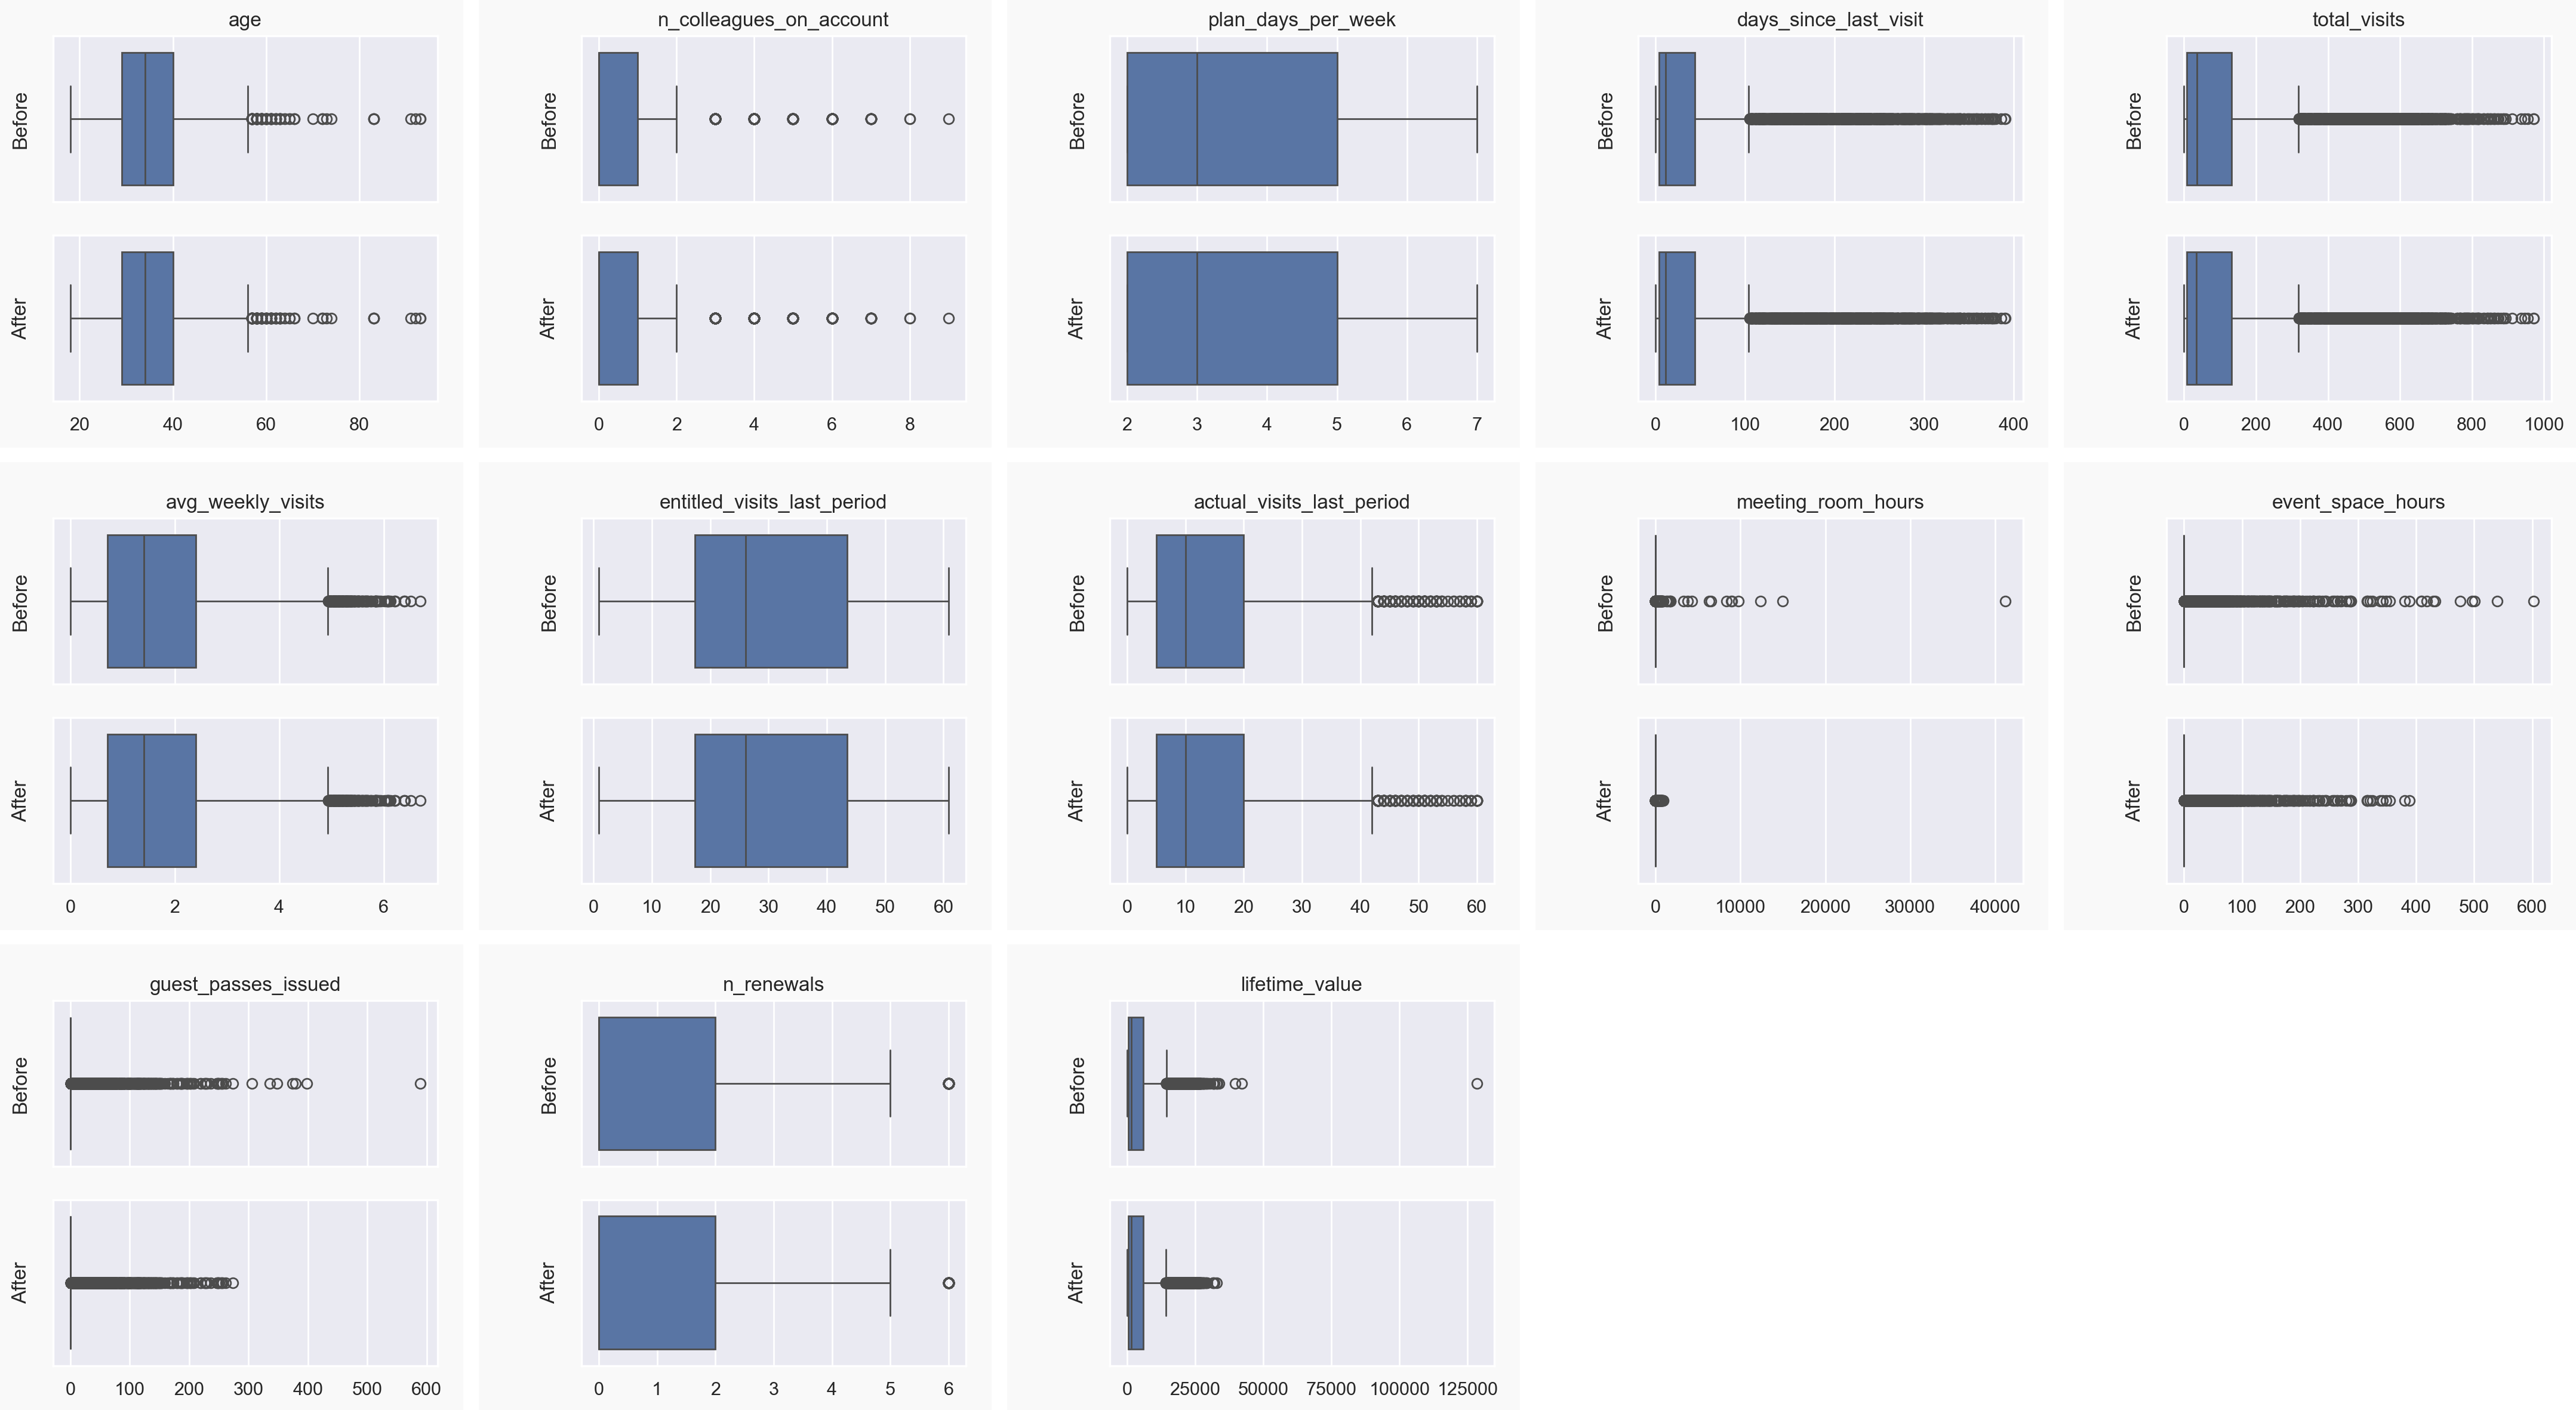

In [73]:
# Box plots before and after outlier removal
fig = plt.figure(figsize=(22, 12))
subfigs = fig.subfigures(3, ceil(len(metric_features) / 3), wspace=.03, hspace=.03)

for sfig, feat in zip(subfigs.flatten(), metric_features):
    axes = sfig.subplots(2, 1, sharex=True)

    sns.boxplot(x=df_before_outliers[feat], ax=axes[0])
    axes[0].set_ylabel("Before")
    axes[0].set_title(feat)

    sns.boxplot(x=df[feat], ax=axes[1])
    axes[1].set_ylabel("After")
    axes[1].set_xlabel("")

    sfig.set_facecolor("#F9F9F9")
    sfig.subplots_adjust(left=.2, right=.95, bottom=.1)

for sfig in subfigs.flatten()[len(metric_features):]:
    sfig.set_visible(False)

plt.show()

## 9. Missing Value Imputation

In [74]:
df.isna().sum()[lambda s: s > 0]

age                         676
gender                      505
country                     412
n_colleagues_on_account     144
membership_end             3898
total_visits                 49
avg_weekly_visits            41
meeting_room_hours          400
event_space_hours             8
guest_passes_issued         203
n_renewals                   65
lifetime_value             2786
dtype: int64

`membership_end` is empty on purpose (active members), so it is not imputed.

Before choosing how to impute, what *kind* of missingness is it (lab06: MCAR / MAR / MNAR)? If the share of
missing values changes with an observed variable, the values are Missing At Random (MAR) and that variable
should be used to impute them.

In [75]:
# % missing per plan tier
check_feats = ["age", "gender", "country", "lifetime_value"]
pd.DataFrame({feat: df[feat].isna().groupby(df["plan_tier"]).mean() * 100 for feat in check_feats}).round(1)

,age,gender,country,lifetime_value
plan_tier,,,,
dedicated_desk,4.9,4.2,2.7,22.0
flex,4.3,3.2,2.9,18.3
full_time,4.6,3.5,2.5,21.4
hot_desk,4.4,3.0,2.6,15.4
private_office,5.6,4.3,3.3,25.0


In [76]:
# % missing for active members vs members who left, and for individual vs team accounts
is_active = df["membership_end"].isna().map({True: "active", False: "left"})
pd.concat([
    pd.DataFrame({feat: df[feat].isna().groupby(is_active).mean() * 100 for feat in check_feats}),
    pd.DataFrame({feat: df[feat].isna().groupby(df["is_team_account"]).mean() * 100 for feat in check_feats})
      .rename(index={False: "individual", True: "team"}),
]).round(1)

,age,gender,country,lifetime_value
active,4.8,3.4,2.7,19.2
left,4.4,3.3,2.7,18.2
individual,4.3,3.4,2.7,18.2
team,5.0,3.3,2.8,19.2


In [77]:
# lifetime_value: % missing by number of renewals (a proxy for how long the member stayed)
(df["lifetime_value"].isna().groupby(df["n_renewals"]).mean() * 100).round(1)

n_renewals
0.0    17.0
1.0    18.2
2.0    20.4
3.0    20.6
4.0    22.2
5.0    24.8
6.0    22.8
Name: lifetime_value, dtype: float64

| Feature | Evidence | Type | Treatment |
|---|---|---|---|
| `meeting_room_hours`, `guest_passes_issued` | Missing mostly when the add-on was never used (5.2) | MAR | 0 if never used (done in 7), median otherwise |
| `lifetime_value` | Missing more often in the expensive tiers and for members with more renewals | MAR | Plan price × months (uses tier and tenure) |
| `age`, `gender`, `country` | About the same share in every tier, status and account type | Consistent with MCAR (MNAR cannot be ruled out for a personal question like gender) | Median (`age`), `Unknown` (`gender`, `country`) |
| `total_visits`, `avg_weekly_visits`, `n_colleagues_on_account`, `n_renewals`, hours | Created by us when removing impossible values (7) | Not a property of the data | Rules where possible, median otherwise |

### 9.1 Rule-based imputation

Three features have a better estimate than a median:
- `n_colleagues_on_account` on team accounts: the overall median (0) is impossible for a team account,
  so we use the median of the team accounts.
- `lifetime_value`: section 5.7 showed that it is *monthly plan price × months*. That is far more precise than a
  single median for everyone (a private office for 3 years and a hot desk for 1 month would get the same value).
- `total_visits` / `avg_weekly_visits`: section 5.6 showed that one is the other divided by the weeks as a member,
  so each can be rebuilt from the other (a median would break that relation).

In [78]:
team = df["is_team_account"] == True
team_median = df.loc[team, "n_colleagues_on_account"].median()
df.loc[team & df["n_colleagues_on_account"].isna(), "n_colleagues_on_account"] = team_median
print("Median colleagues on team accounts:", team_median)
print("Missing n_colleagues_on_account:", df["n_colleagues_on_account"].isna().sum())

Median colleagues on team accounts: 2.0
Missing n_colleagues_on_account: 0


In [79]:
tenure_months = (df["membership_end"].fillna(extraction_date) - df["membership_start"]).dt.days / 30.44
expected_ltv = df["plan_tier"].map(tier_monthly_price) * tenure_months

ltv_missing = df["lifetime_value"].isna()
df.loc[ltv_missing, "lifetime_value"] = expected_ltv[ltv_missing].round(2)
print("lifetime_value imputed:", ltv_missing.sum(), f"({ltv_missing.mean() * 100:.1f}% of rows)")
print("Missing lifetime_value:", df["lifetime_value"].isna().sum())

lifetime_value imputed: 2786 (18.5% of rows)
Missing lifetime_value: 0


In [80]:
weeks_member = (df["membership_end"].fillna(extraction_date) - df["membership_start"]).dt.days / 7
rebuilt_total = (df["avg_weekly_visits"] * weeks_member).round()
rebuilt_weekly = (df["total_visits"] / weeks_member).round(2)

# only rebuild when there is at least a week of history and the result is itself plausible (rules from 5.5)
fill_total = df["total_visits"].isna() & (weeks_member >= 1) & (rebuilt_total <= 3 * 365)
fill_weekly = df["avg_weekly_visits"].isna() & (weeks_member >= 1) & (rebuilt_weekly <= 7)
df.loc[fill_total, "total_visits"] = rebuilt_total[fill_total]
df.loc[fill_weekly, "avg_weekly_visits"] = rebuilt_weekly[fill_weekly]

print("total_visits rebuilt from avg_weekly_visits:", fill_total.sum(),
      "| still missing:", df["total_visits"].isna().sum())
print("avg_weekly_visits rebuilt from total_visits:", fill_weekly.sum(),
      "| still missing:", df["avg_weekly_visits"].isna().sum())

total_visits rebuilt from avg_weekly_visits: 41 | still missing: 8
avg_weekly_visits rebuilt from total_visits: 29 | still missing: 12


Limitation of the `lifetime_value` rule: it only counts the plan, not add-ons, so heavy add-on users with an
unknown value are slightly underestimated. Only about 5% of members pay more than ~2.4 times their plan
(95th percentile in 5.7), so this affects few rows.

### 9.2 `gender` and `country`

We do **not** fill them with the mode. Filling ~500 genders with "Female" and ~400 countries with "Portugal"
would invent people that do not exist, and for a personal question like gender, not answering can be a choice
(MNAR) that the data cannot rule out. We use an explicit `Unknown` category instead, the same approach the
source system already uses for `industry`. These features describe the member; they are better for profiling segments than for clustering.

In [81]:
for feat in ["gender", "country"]:
    df[feat] = df[feat].fillna("Unknown")
    print(feat, "->", df[feat].value_counts().to_dict())

gender -> {'Female': 7682, 'Male': 6406, 'Unknown': 505, 'Other': 489}
country -> {'Portugal': 10256, 'United Kingdom': 1145, 'Germany': 881, 'Spain': 713, 'France': 523, 'Netherlands': 475, 'Other (Europe)': 441, 'Unknown': 412, 'Ireland': 236}


### 9.3 Remaining metric features: median vs KNN imputation (lab06)

In [82]:
impute_features = [feat for feat in metric_features if df[feat].isna().any()]
print("Features still with missing values:", impute_features)

# skewness tells us whether the mean or the median is the better central value
df[impute_features].skew().round(2)

Features still with missing values: ['age', 'total_visits', 'avg_weekly_visits', 'meeting_room_hours', 'event_space_hours', 'guest_passes_issued', 'n_renewals']


age                    0.44
total_visits           2.14
avg_weekly_visits      0.92
meeting_room_hours     5.03
event_space_hours      7.64
guest_passes_issued    5.90
n_renewals             1.42
dtype: float64

In [83]:
# Option 1: median
df_central = df.copy()
medians = df_central[impute_features].median()
df_central[impute_features] = df_central[impute_features].fillna(medians)

In [84]:
# Option 2: KNN imputer, using all metric features to find the neighbours
df_neighbors = df.copy()
imputer = KNNImputer(n_neighbors=5, weights="uniform")
df_neighbors[metric_features] = imputer.fit_transform(df_neighbors[metric_features])

In [85]:
pd.DataFrame({
    "original_mean": df[impute_features].mean(),
    "median_imputed_mean": df_central[impute_features].mean(),
    "knn_imputed_mean": df_neighbors[impute_features].mean(),
    "original_std": df[impute_features].std(),
    "median_imputed_std": df_central[impute_features].std(),
    "knn_imputed_std": df_neighbors[impute_features].std(),
}).round(2)

,original_mean,median_imputed_mean,knn_imputed_mean,original_std,median_imputed_std,knn_imputed_std
age,34.75,34.72,34.76,8.40,8.21,8.25
total_visits,109.08,109.04,109.18,164.49,164.45,164.55
avg_weekly_visits,1.71,1.71,1.71,1.29,1.29,1.29
meeting_room_hours,21.69,21.12,22.10,62.13,61.40,62.08
event_space_hours,4.81,4.81,4.82,23.07,23.07,23.07
guest_passes_issued,5.51,5.44,5.61,20.96,20.83,20.94
n_renewals,1.02,1.01,1.02,1.34,1.34,1.34


- **Both methods give almost the same means and standard deviations,** because few values are missing in each
  feature by now (the big gaps were already handled by rules).
- **We keep the median:** it is simpler, robust to the strong skew of the usage features (skewness up to 7.6),
  and KNN would need scaled features first. Without scaling, `lifetime_value` (thousands of euros) dominates the
  distance and the "neighbours" would just be members with a similar revenue.

In [86]:
# keep the median imputation
df = df_central.copy()

# only membership_end should still be empty (= active members)
df.isna().sum()[lambda s: s > 0]

membership_end    3898
dtype: int64

In [87]:
# final coherence check on the cleaned data
expected_days = expected_plan_days(df)
end_date = df["membership_end"]
final_checks = {
    "plan_days_per_week not matching plan_tier": df["plan_days_per_week"] != expected_days,
    "entitled visits above the plan": df[ent] > df["plan_days_per_week"] * weeks_last_period + 0.05,
    "actual visits above entitled visits": df["actual_visits_last_period"] > df[ent],
    "team account with 0 colleagues": (df["is_team_account"] == True) & (df["n_colleagues_on_account"] == 0),
    "individual account with colleagues": (df["is_team_account"] == False) & (df["n_colleagues_on_account"] > 0),
    "uses_meeting_rooms False but hours > 0": (df["uses_meeting_rooms"] == False) & (df["meeting_room_hours"] > 0),
    "age outside 18-100": (df["age"] < 18) | (df["age"] > 100),
    "negative or zero lifetime_value": df["lifetime_value"] <= 0,
    "negative values": (df[non_negative_features + ["days_since_last_visit"]] < 0).any(axis=1),
    "contradictory dates": ((end_date < df["membership_start"]) | (df["last_badge_swipe"] < df["membership_start"])
                            | (df["last_badge_swipe"] > end_date) | (df["last_badge_swipe"] > extraction_date)),
}
pd.Series({check: mask.sum() for check, mask in final_checks.items()}, name="n_rows")

plan_days_per_week not matching plan_tier    0
entitled visits above the plan               0
actual visits above entitled visits          0
team account with 0 colleagues               0
individual account with colleagues           0
uses_meeting_rooms False but hours > 0       0
age outside 18-100                           0
negative or zero lifetime_value              0
negative values                              0
contradictory dates                          0
Name: n_rows, dtype: int64

In [88]:
print("Rows kept:", df.shape[0], "of", df_original.shape[0],
      f"({df.shape[0] / df_original.shape[0] * 100:.2f}%)")

Rows kept: 15082 of 15465 (97.52%)


## 10. `clean_data()` – reusable cleaning function

All the steps above in one function, so Maria and Matilde can get the cleaned data with one call.
It uses the reference values estimated in this notebook (`extraction_date`, `tier_monthly_price`,
`weeks_last_period`, the category maps and the outlier limits), so it must be run after the cells above.

In [89]:
def clean_data(data):
    """Apply every cleaning step of this notebook to the raw ACDC dataframe."""
    data = data.copy()

    # 5.1 duplicates and 5.2 empty strings
    data = data.drop_duplicates()
    data = data.replace("", np.nan)

    # 5.3 data types
    data["uses_print"] = data["uses_print"].astype(bool)
    for feat in date_features:
        iso_format = pd.to_datetime(data[feat], format="%Y-%m-%d", errors="coerce")
        day_first_format = pd.to_datetime(data[feat], format="%d/%m/%Y", errors="coerce")
        data[feat] = iso_format.fillna(day_first_format)
    data["lifetime_value"] = (data["lifetime_value"].str.replace("€", "", regex=False)
                              .str.replace(",", "", regex=False).str.strip().astype(float))

    # 5.4 inconsistent categories
    for feat, mapping in category_maps.items():
        data[feat] = data[feat].replace(mapping)

    # 7.1-7.2 impossible values
    data.loc[(data["age"] < 18) | (data["age"] > 100), "age"] = np.nan
    data.loc[(data["n_colleagues_on_account"] == -1) & (data["is_team_account"] == False),
             "n_colleagues_on_account"] = 0
    for feat in non_negative_features:
        data.loc[data[feat] < 0, feat] = np.nan
    data.loc[data["avg_weekly_visits"] > 7, "avg_weekly_visits"] = np.nan
    data.loc[data["total_visits"] > 3 * 365, "total_visits"] = np.nan

    # 7.3 plan days must match the tier (and entitlements calculated with the wrong days)
    expected = expected_plan_days(data)
    wrong = data["plan_tier"].notna() & (data["plan_days_per_week"] != expected)
    old_days = data["plan_days_per_week"].copy()
    data.loc[wrong, "plan_days_per_week"] = expected[wrong]
    nine = wrong & (old_days == 9) & (data[ent] > data["plan_days_per_week"] * weeks_last_period + 0.05)
    data.loc[nine, ent] = (data[ent] / 9 * data["plan_days_per_week"])[nine].round(2)
    zero = wrong & (old_days == 0) & (data[ent] == 0)
    data.loc[zero, ent] = (data["plan_days_per_week"] * weeks_last_period)[zero].round(2)

    # 7.4 missing plan tier
    for days, tier in days_tier.items():
        data.loc[data["plan_tier"].isna() & (data["plan_days_per_week"] == days), "plan_tier"] = tier
    tier_5 = data.loc[data["plan_days_per_week"] == 5, "plan_tier"].mode()[0]
    data.loc[data["plan_tier"].isna() & (data["plan_days_per_week"] == 5), "plan_tier"] = tier_5

    # 7.5-7.6 add-on coherence
    data.loc[(data["uses_meeting_rooms"] == False) & (data["meeting_room_hours"] > 0), "uses_meeting_rooms"] = True
    data.loc[data["meeting_room_hours"].isna() & (data["uses_meeting_rooms"] == False), "meeting_room_hours"] = 0
    data.loc[data["guest_passes_issued"].isna() & (data["uses_guest_passes"] == False), "guest_passes_issued"] = 0

    # 7.7-7.9 dates and recency
    end = data["membership_end"].where(data["membership_end"].dt.year != 1970)
    bad_dates = ((end < data["membership_start"]) | (data["last_badge_swipe"] < data["membership_start"])
                 | (data["last_badge_swipe"] > end) | (data["last_badge_swipe"] > extraction_date))
    data = data[~bad_dates].copy()
    data.loc[data["membership_end"].dt.year == 1970, "membership_end"] = pd.NaT
    data["days_since_last_visit"] = (data["membership_end"].fillna(extraction_date)
                                     - data["last_badge_swipe"]).dt.days

    # 7.10-7.11 lifetime_value placeholders and lost decimal points
    data.loc[data["lifetime_value"] <= 0, "lifetime_value"] = np.nan
    months = (data["membership_end"].fillna(extraction_date) - data["membership_start"]).dt.days / 30.44
    expected_value = data["plan_tier"].map(tier_monthly_price) * months
    lost = (expected_value > 0) & (data["lifetime_value"] / expected_value > 20)
    data.loc[lost, "lifetime_value"] = data.loc[lost, "lifetime_value"] / 100

    # 8. outliers (manual limits)
    keep = pd.Series(True, index=data.index)
    for feat, limit in manual_limits.items():
        keep = keep & ((data[feat] <= limit) | data[feat].isna())
    data = data[keep].copy()

    # 9.1 rule-based imputation
    is_team = data["is_team_account"] == True
    data.loc[is_team & data["n_colleagues_on_account"].isna(), "n_colleagues_on_account"] = \
        data.loc[is_team, "n_colleagues_on_account"].median()
    months = (data["membership_end"].fillna(extraction_date) - data["membership_start"]).dt.days / 30.44
    expected_value = data["plan_tier"].map(tier_monthly_price) * months
    missing_value = data["lifetime_value"].isna()
    data.loc[missing_value, "lifetime_value"] = expected_value[missing_value].round(2)

    weeks = (data["membership_end"].fillna(extraction_date) - data["membership_start"]).dt.days / 7
    new_total = (data["avg_weekly_visits"] * weeks).round()
    new_weekly = (data["total_visits"] / weeks).round(2)
    fill_t = data["total_visits"].isna() & (weeks >= 1) & (new_total <= 3 * 365)
    fill_w = data["avg_weekly_visits"].isna() & (weeks >= 1) & (new_weekly <= 7)
    data.loc[fill_t, "total_visits"] = new_total[fill_t]
    data.loc[fill_w, "avg_weekly_visits"] = new_weekly[fill_w]

    # 9.2 unknown gender / country
    data[["gender", "country"]] = data[["gender", "country"]].fillna("Unknown")

    # 9.3 median for the remaining metric features
    data[metric_features] = data[metric_features].fillna(data[metric_features].median())

    return data

In [90]:
# check: the function gives exactly the same result as the step-by-step cleaning above
df_clean = clean_data(df_original)

print("Shape step-by-step:", df.shape, "| Shape clean_data():", df_clean.shape)
print("Identical:", df_clean.reset_index(drop=True).equals(df.reset_index(drop=True)))

Shape step-by-step: (15082, 31) | Shape clean_data(): (15082, 31)
Identical: True


In [91]:
# save the cleaned data for the team
# (read it back with: pd.read_csv(path, sep=";", parse_dates=["membership_start", "membership_end", "last_badge_swipe"]))
df_clean.to_csv(os.path.join("..", "..", "data", "acdc_clean.csv"), sep=";", index=False)

## 11. Summary of Data Quality Issues
| Issue | Rows affected | Treatment |
|---|---|---|
| Duplicated rows | 15 | Dropped (exact copies) |
| Inconsistent category labels | gender 12 → 3, country 33 → 8, industry 43 → 11, plan_tier 19 → 5 labels | Mapped to standard labels |
| `uses_print` stored as 0/1 | all | Converted to boolean |
| Dates stored as text in two formats | all | Parsed; `/` dates proven to be dd/mm/yyyy |
| `lifetime_value` stored as text (€, thousands separators) | all | Converted to numbers, no value lost |
| Impossible ages (< 18 or > 100) | 143 | Set to missing → median |
| `n_colleagues_on_account = -1` | 565 | 0 on individual accounts (412); median of team accounts (153) |
| Other negative counts/hours | 66 renewals, 31 hours/passes | Set to missing → median |
| Impossible visits: `total_visits` negative or > 1095, `avg_weekly_visits` > 7 | 42 + 7, 42 | Set to missing → rebuilt from each other using the dates (41 and 29); the rest → median |
| `plan_days_per_week` not matching the tier | 97 | Set to the tier's days |
| Entitled visits calculated with those wrong days | 40 | Rescaled to the tier's days (30 rows with 9 days); 0 entitled visits → a full period (10 rows with 0 days) |
| Missing `plan_tier` | 105 | Inferred from the days (56); 5-day plans → most frequent 5-day tier (49) |
| `uses_meeting_rooms` False with hours > 0 | 55 | Flag set to True |
| Missing usage for add-ons never used | 902 meeting rooms, 1,066 guest passes | Set to 0 |
| Contradictory dates | 333 (2.2%) | Removed (impossible to know which date is wrong) |
| `membership_end = 1970-01-01` | 3,954 | Empty date = still active (proven with the extraction date) |
| `days_since_last_visit` = 999 placeholder / negative | 1,298 / 56 | Recalculated from the dates (99.5% match with the plausible originals) |
| `lifetime_value` 0 or negative | 1,784 | Placeholders → missing |
| `lifetime_value` with a lost decimal point | 83 | Divided by 100 |
| `lifetime_value` missing (incl. the above) | 2,786 (18.5%) | Monthly plan price × months as a member |
| Extreme usage values | 35 | Removed (manual limits) |
| Missing `gender` / `country` | 505 / 412 | `Unknown` category (not the mode) |
| `actual_visits_last_period` > entitled | 8 | Side effect of the wrong 0 days; solved by the entitlement fix |

**Checks that passed without changes:** visits agree with the dates (`avg_weekly_visits` = `total_visits` / weeks,
median ratio 1.00), entitlements follow the plan (days × 8.7 weeks) once the wrong days are fixed, team/individual accounts agree with the
number of colleagues, and event-space / guest-pass flags agree with their usage.

**Type of missingness:** add-on usage and `lifetime_value` are MAR (they depend on the add-on flag, the tier and
the tenure, so those were used to impute them); `age`, `gender` and `country` look MCAR (same share in every group).

**Result:** 15,082 of 15,465 rows kept (97.5%); every coherence rule passes on the cleaned data.

**Risks for clustering:**
- **`lifetime_value` is almost "plan price × tenure"** (and 18.5% of it is imputed exactly that way), so it will be
  strongly correlated with plan tier and tenure. The part that really tells members apart is the extra revenue
  from add-ons, so a feature such as value per month vs. plan price is worth building.
- **The usage features are zero-inflated and very skewed,** so they need scaling (and probably a transformation)
  before distance-based clustering.
- **`Unknown` categories** (industry ~4.4%, gender ~3.3%, country ~2.7%) can form artificial groups if used as
  clustering inputs; they are safer for profiling.
- **The tier order in the metadata is not a price order** (`dedicated_desk` costs more than `full_time`), which
  matters when describing value segments.
- **Rules only catch the errors we thought of;** errors that only show up in combinations of features need a
  multivariate method (bonus: anomaly detection).